In [1]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import pandas as pd
import numpy as np
import statistics as stats
from scipy.stats import iqr
import csv
%matplotlib inline
from sklearn import metrics
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import classification_report
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import Perceptron
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from sklearn.preprocessing import LabelEncoder

In [2]:
test_df = pd.read_csv('Kaggle/test.csv')
train_df = pd.read_csv('Kaggle/train.csv')

/var/folders/c7/s_7n84_s6g92fqcd6c0jf1nh0000gn/T/ipykernel_17268/3290425567.py:2: DtypeWarning: Columns (26) have mixed types. Specify dtype option on import or set low_memory=False.
  train_df = pd.read_csv('Kaggle/train.csv')


In [3]:
test_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 27 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   ID                        50000 non-null  object 
 1   Customer_ID               50000 non-null  object 
 2   Month                     50000 non-null  object 
 3   Name                      44985 non-null  object 
 4   Age                       50000 non-null  object 
 5   SSN                       50000 non-null  object 
 6   Occupation                50000 non-null  object 
 7   Annual_Income             50000 non-null  object 
 8   Monthly_Inhand_Salary     42502 non-null  float64
 9   Num_Bank_Accounts         50000 non-null  int64  
 10  Num_Credit_Card           50000 non-null  int64  
 11  Interest_Rate             50000 non-null  int64  
 12  Num_of_Loan               50000 non-null  object 
 13  Type_of_Loan              44296 non-null  object 
 14  Delay_

In [4]:
train_df.head(3)

,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,...,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,0x1602,CUS_0xd40,January,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,1824.843333,3,...,_,809.98,26.822620,22 Years and 1 Months,No,49.574949,80.41529543900253,High_spent_Small_value_payments,312.49408867943663,Good
1,0x1603,CUS_0xd40,February,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,NaN,3,...,Good,809.98,31.944960,NaN,No,49.574949,118.28022162236736,Low_spent_Large_value_payments,284.62916249607184,Good
2,0x1604,CUS_0xd40,March,Aaron Maashoh,-500,821-00-0265,Scientist,19114.12,NaN,3,...,Good,809.98,28.609352,22 Years and 3 Months,No,49.574949,81.699521264648,Low_spent_Medium_value_payments,331.2098628537912,Good


In [5]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 28 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   ID                        100000 non-null  object 
 1   Customer_ID               100000 non-null  object 
 2   Month                     100000 non-null  object 
 3   Name                      90015 non-null   object 
 4   Age                       100000 non-null  object 
 5   SSN                       100000 non-null  object 
 6   Occupation                100000 non-null  object 
 7   Annual_Income             100000 non-null  object 
 8   Monthly_Inhand_Salary     84998 non-null   float64
 9   Num_Bank_Accounts         100000 non-null  int64  
 10  Num_Credit_Card           100000 non-null  int64  
 11  Interest_Rate             100000 non-null  int64  
 12  Num_of_Loan               100000 non-null  object 
 13  Type_of_Loan              88592 non-null   ob

In [6]:
# I will use the train_test_split library to split the data so will append the two data sets

df = pd.concat([train_df, test_df], ignore_index=True)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 28 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   ID                        150000 non-null  object 
 1   Customer_ID               150000 non-null  object 
 2   Month                     150000 non-null  object 
 3   Name                      135000 non-null  object 
 4   Age                       150000 non-null  object 
 5   SSN                       150000 non-null  object 
 6   Occupation                150000 non-null  object 
 7   Annual_Income             150000 non-null  object 
 8   Monthly_Inhand_Salary     127500 non-null  float64
 9   Num_Bank_Accounts         150000 non-null  int64  
 10  Num_Credit_Card           150000 non-null  int64  
 11  Interest_Rate             150000 non-null  int64  
 12  Num_of_Loan               150000 non-null  object 
 13  Type_of_Loan              132888 non-null  o

# Process

Steps:
* Drop irrelevant columns
* Drop NaN for Credit Score
* Drop Credit Score = Standard, we want a binary classifier
* Convert Poor = 0 adn Good = 1
* Convert string columns to numeric
* Convert strings to Numeric through coerce and drop NaN

In [10]:
df.drop(['Name','Month','SSN','ID','Customer_ID'], axis=1, inplace=True)

In [11]:
# All these columns do not provide data that would effect credit score

In [12]:
df['Type_of_Loan'].value_counts()

Type_of_Loan
Not Specified                                                                                                                         2112
Credit-Builder Loan                                                                                                                   1920
Personal Loan                                                                                                                         1908
Debt Consolidation Loan                                                                                                               1896
Student Loan                                                                                                                          1860
                                                                                                                                      ... 
Not Specified, Mortgage Loan, Auto Loan, and Payday Loan                                                                                12
Payday Loan, M

In [13]:
# This would be impossible to convert into a dummy variable

In [14]:
df.drop(['Type_of_Loan'], axis=1, inplace=True)

In [15]:
df['Credit_Mix'].value_counts()

Credit_Mix
Standard    54858
Good        36597
_           30000
Bad         28545
Name: count, dtype: int64

In [16]:
# Credit mix is too similar to Credit_Score so will drop this column

In [17]:
df.drop(['Credit_Mix'],axis=1, inplace=True)

In [18]:
df.dropna(subset=['Credit_Score'], inplace=True)

In [19]:
# removing Standard credit score, replacing poor and good with 0 and 1 and covnerting Credit Score to an integer

In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 100000 entries, 0 to 99999
Data columns (total 21 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   Age                       100000 non-null  object 
 1   Occupation                100000 non-null  object 
 2   Annual_Income             100000 non-null  object 
 3   Monthly_Inhand_Salary     84998 non-null   float64
 4   Num_Bank_Accounts         100000 non-null  int64  
 5   Num_Credit_Card           100000 non-null  int64  
 6   Interest_Rate             100000 non-null  int64  
 7   Num_of_Loan               100000 non-null  object 
 8   Delay_from_due_date       100000 non-null  int64  
 9   Num_of_Delayed_Payment    92998 non-null   object 
 10  Changed_Credit_Limit      100000 non-null  object 
 11  Num_Credit_Inquiries      98035 non-null   float64
 12  Outstanding_Debt          100000 non-null  object 
 13  Credit_Utilization_Ratio  100000 non-null  float64

In [21]:
pd.set_option('future.no_silent_downcasting', True)

In [22]:
df = df[(df['Credit_Score']=='Poor') | (df['Credit_Score']=='Good')]

In [23]:
df['Credit_Score']=df['Credit_Score'].replace({'Poor':0,'Good':1})

In [24]:
df['Credit_Score']=df['Credit_Score'].astype('int')

In [25]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 46826 entries, 0 to 99999
Data columns (total 21 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Age                       46826 non-null  object 
 1   Occupation                46826 non-null  object 
 2   Annual_Income             46826 non-null  object 
 3   Monthly_Inhand_Salary     39711 non-null  float64
 4   Num_Bank_Accounts         46826 non-null  int64  
 5   Num_Credit_Card           46826 non-null  int64  
 6   Interest_Rate             46826 non-null  int64  
 7   Num_of_Loan               46826 non-null  object 
 8   Delay_from_due_date       46826 non-null  int64  
 9   Num_of_Delayed_Payment    43569 non-null  object 
 10  Changed_Credit_Limit      46826 non-null  object 
 11  Num_Credit_Inquiries      45924 non-null  float64
 12  Outstanding_Debt          46826 non-null  object 
 13  Credit_Utilization_Ratio  46826 non-null  float64
 14  Credit_Hist

In [26]:
df.head()

,Age,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,...,Num_Credit_Inquiries,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,23,Scientist,19114.12,1824.843333,3,4,3,4,3,7,...,4.0,809.98,26.822620,22 Years and 1 Months,No,49.574949,80.41529543900253,High_spent_Small_value_payments,312.49408867943663,1
1,23,Scientist,19114.12,NaN,3,4,3,4,-1,NaN,...,4.0,809.98,31.944960,NaN,No,49.574949,118.28022162236736,Low_spent_Large_value_payments,284.62916249607184,1
2,-500,Scientist,19114.12,NaN,3,4,3,4,3,7,...,4.0,809.98,28.609352,22 Years and 3 Months,No,49.574949,81.699521264648,Low_spent_Medium_value_payments,331.2098628537912,1
3,23,Scientist,19114.12,NaN,3,4,3,4,5,4,...,4.0,809.98,31.377862,22 Years and 4 Months,No,49.574949,199.4580743910713,Low_spent_Small_value_payments,223.45130972736786,1
4,23,Scientist,19114.12,1824.843333,3,4,3,4,6,NaN,...,4.0,809.98,24.797347,22 Years and 5 Months,No,49.574949,41.420153086217326,High_spent_Medium_value_payments,341.48923103222177,1


In [27]:
# There are a number of columns that should be numeric but becasue of likely typos in some field the data frame reads them as an object

In [28]:
columns_convert_num = ['Age','Annual_Income','Num_of_Loan','Num_of_Delayed_Payment','Changed_Credit_Limit','Outstanding_Debt','Amount_invested_monthly','Monthly_Balance']
df[columns_convert_num] = df[columns_convert_num].apply(pd.to_numeric, errors='coerce')

In [29]:
# This will create NaN but will drop NaN at the end

In [30]:
#Credit_History Age is in the wrong format: e.g. 22 years and 1 Month. Convert this into just years by rounding down to nearest whole year.

In [31]:
# credit history age is written like 22 Years and 1 Months, I need to convert this into just years. I will use the ' ' as a delimeter.

df['Credit_History_Age'] = df['Credit_History_Age'].str.split(' ').str[0]

# this will create some null values were the credit history age is less than a year so we need to make the Nan = 0

df['Credit_History_Age'] = df['Credit_History_Age'].fillna(0)

# We also want this field to be an integer

df['Credit_History_Age'] = df['Credit_History_Age'].astype('int64')

In [32]:
string_columns = ['Occupation','Payment_of_Min_Amount','Payment_Behaviour']

In [33]:
for i in string_columns:
    print(df[i].value_counts())

Occupation
_______          3274
Engineer         3114
Scientist        3048
Teacher          3038
Accountant       3007
Entrepreneur     2976
Lawyer           2972
Developer        2926
Mechanic         2920
Journalist       2898
Architect        2878
Manager          2830
Media_Manager    2806
Musician         2780
Doctor           2743
Writer           2616
Name: count, dtype: int64
Payment_of_Min_Amount
Yes    22620
No     18443
NM      5763
Name: count, dtype: int64
Payment_Behaviour
Low_spent_Small_value_payments      12398
High_spent_Medium_value_payments     7963
Low_spent_Medium_value_payments      6693
High_spent_Large_value_payments      6151
High_spent_Small_value_payments      5202
Low_spent_Large_value_payments       4811
!@9#%8                               3608
Name: count, dtype: int64


In [34]:
# Have to assume that Ocupation: _____ is no occupation and Payment_Behaviour: !@9#%8 is random spending behaviour

In [35]:
df = pd.get_dummies(df, columns=string_columns, drop_first=True,dtype=int)

In [36]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 46826 entries, 0 to 99999
Data columns (total 41 columns):
 #   Column                                              Non-Null Count  Dtype  
---  ------                                              --------------  -----  
 0   Age                                                 44465 non-null  float64
 1   Annual_Income                                       43481 non-null  float64
 2   Monthly_Inhand_Salary                               39711 non-null  float64
 3   Num_Bank_Accounts                                   46826 non-null  int64  
 4   Num_Credit_Card                                     46826 non-null  int64  
 5   Interest_Rate                                       46826 non-null  int64  
 6   Num_of_Loan                                         44589 non-null  float64
 7   Delay_from_due_date                                 46826 non-null  int64  
 8   Num_of_Delayed_Payment                              42298 non-null  float64
 9   

In [37]:
# Check for NaNs
df.isnull().sum()

Age                                                   2361
Annual_Income                                         3345
Monthly_Inhand_Salary                                 7115
Num_Bank_Accounts                                        0
Num_Credit_Card                                          0
Interest_Rate                                            0
Num_of_Loan                                           2237
Delay_from_due_date                                      0
Num_of_Delayed_Payment                                4528
Changed_Credit_Limit                                  1000
Num_Credit_Inquiries                                   902
Outstanding_Debt                                       473
Credit_Utilization_Ratio                                 0
Credit_History_Age                                       0
Total_EMI_per_month                                      0
Amount_invested_monthly                               4197
Monthly_Balance                                        5

In [38]:
df.dropna(inplace=True)

In [39]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 25712 entries, 0 to 99997
Data columns (total 41 columns):
 #   Column                                              Non-Null Count  Dtype  
---  ------                                              --------------  -----  
 0   Age                                                 25712 non-null  float64
 1   Annual_Income                                       25712 non-null  float64
 2   Monthly_Inhand_Salary                               25712 non-null  float64
 3   Num_Bank_Accounts                                   25712 non-null  int64  
 4   Num_Credit_Card                                     25712 non-null  int64  
 5   Interest_Rate                                       25712 non-null  int64  
 6   Num_of_Loan                                         25712 non-null  float64
 7   Delay_from_due_date                                 25712 non-null  int64  
 8   Num_of_Delayed_Payment                              25712 non-null  float64
 9   

In [40]:
df.describe()

,Age,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,...,Occupation_Writer,Occupation________,Payment_of_Min_Amount_No,Payment_of_Min_Amount_Yes,Payment_Behaviour_High_spent_Large_value_payments,Payment_Behaviour_High_spent_Medium_value_payments,Payment_Behaviour_High_spent_Small_value_payments,Payment_Behaviour_Low_spent_Large_value_payments,Payment_Behaviour_Low_spent_Medium_value_payments,Payment_Behaviour_Low_spent_Small_value_payments
count,25712.00000,2.571200e+04,25712.000000,25712.000000,25712.000000,25712.000000,25712.000000,25712.000000,25712.000000,25712.000000,...,25712.000000,25712.000000,25712.000000,25712.000000,25712.000000,25712.000000,25712.000000,25712.000000,25712.000000,25712.000000
mean,107.40028,1.753598e+05,4079.187834,16.923188,23.845131,77.490627,3.105748,22.588091,29.817556,9.548969,...,0.055422,0.068295,0.390713,0.486349,0.131962,0.173615,0.112749,0.104426,0.141685,0.260306
std,669.12351,1.448370e+06,3201.819814,116.637590,133.469252,484.611575,62.198914,16.609652,222.764503,6.641411,...,0.228806,0.252256,0.487920,0.499823,0.338456,0.378786,0.316292,0.305818,0.348733,0.438810
min,-500.00000,7.005930e+03,319.556250,-1.000000,0.000000,1.000000,-100.000000,-5.000000,-3.000000,-6.450000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,24.00000,1.871815e+04,1563.674167,3.000000,4.000000,7.000000,2.000000,10.000000,8.000000,4.590000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,33.00000,3.718810e+04,3045.443333,6.000000,6.000000,15.000000,3.000000,18.000000,14.000000,8.560000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,42.00000,6.969216e+04,5681.175417,8.000000,7.000000,24.000000,6.000000,31.000000,19.000000,13.040000,...,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
max,8697.00000,2.419806e+07,15167.180000,1794.000000,1499.000000,5788.000000,1485.000000,67.000000,4360.000000,35.820000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


There is clearly some incorrect data e.g. Age, Num_Bank_Accounts, Num_of_Loan, Delay_from_due_date, Num_of_Delayed_Payment should all be positive. We should immidiately filter this data out. I aslo will add that Age and credit score age should be positive but less than 100 as its unlikely for there people to be greater than 100. Then perform some inital analysis on variables to identity outliers. 

In [42]:
df = df[
    (df['Age']>0) & (df['Age']<100) & 
    (df['Num_Bank_Accounts']>=0) & 
    (df['Num_of_Loan']>=0) & 
    (df['Num_of_Delayed_Payment']>=0)  & 
    (df['Delay_from_due_date']>=0)]

In [43]:
print(df.describe())

                Age  Annual_Income  Monthly_Inhand_Salary  Num_Bank_Accounts  \
count  23560.000000   2.356000e+04           23560.000000       23560.000000   
mean      33.067699   1.737957e+05            4051.753198          16.790747   
std       10.699812   1.445040e+06            3183.015189         116.206730   
min       14.000000   7.005930e+03             319.556250           0.000000   
25%       24.000000   1.862319e+04            1557.437500           3.000000   
50%       33.000000   3.698356e+04            3038.215833           6.000000   
75%       41.000000   6.907864e+04            5637.960000           8.000000   
max       99.000000   2.419806e+07           15167.180000        1794.000000   

       Num_Credit_Card  Interest_Rate   Num_of_Loan  Delay_from_due_date  \
count     23560.000000   23560.000000  23560.000000         23560.000000   
mean         23.820798      76.703905      7.267360            22.961248   
std         133.066249     480.140304     58.080342

## Preliminary Data Analysis to spot outliers

In [45]:
columns_of_interest = ['Age', 'Annual_Income','Monthly_Inhand_Salary','Num_Bank_Accounts','Num_Credit_Card','Interest_Rate','Num_of_Loan',
                       'Delay_from_due_date','Num_of_Delayed_Payment','Changed_Credit_Limit']

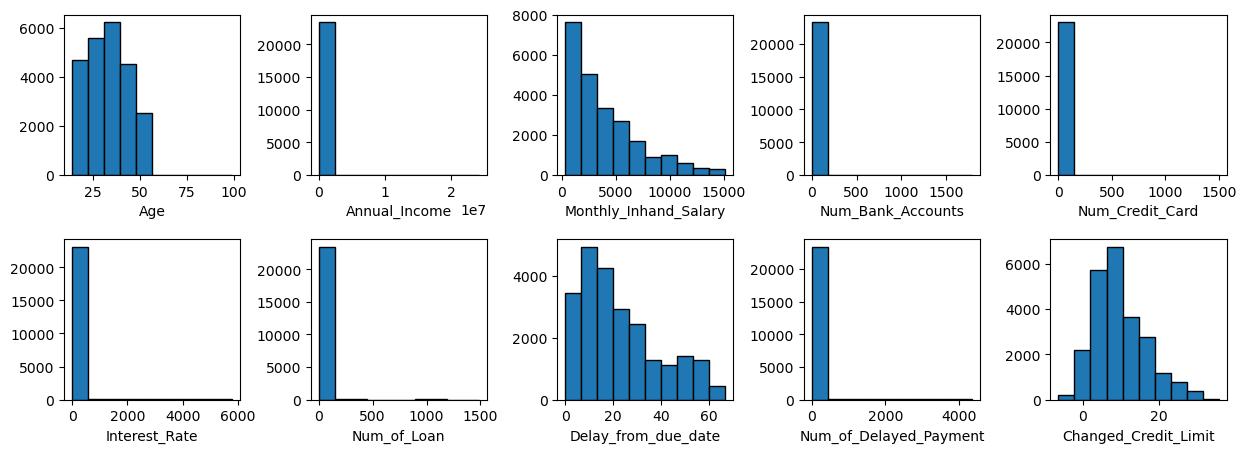

In [46]:
fig, ax = plt.subplots(2,5,figsize=(15,5))
fig.subplots_adjust(hspace=0.4, wspace=0.4)
ax = ax.flatten()

for i, col in enumerate(columns_of_interest):
    ax[i].hist(df[col],edgecolor='black')
    ax[i].set_xlabel(col)
plt.savefig('Numeric_Columns_Histogram.png')
fig

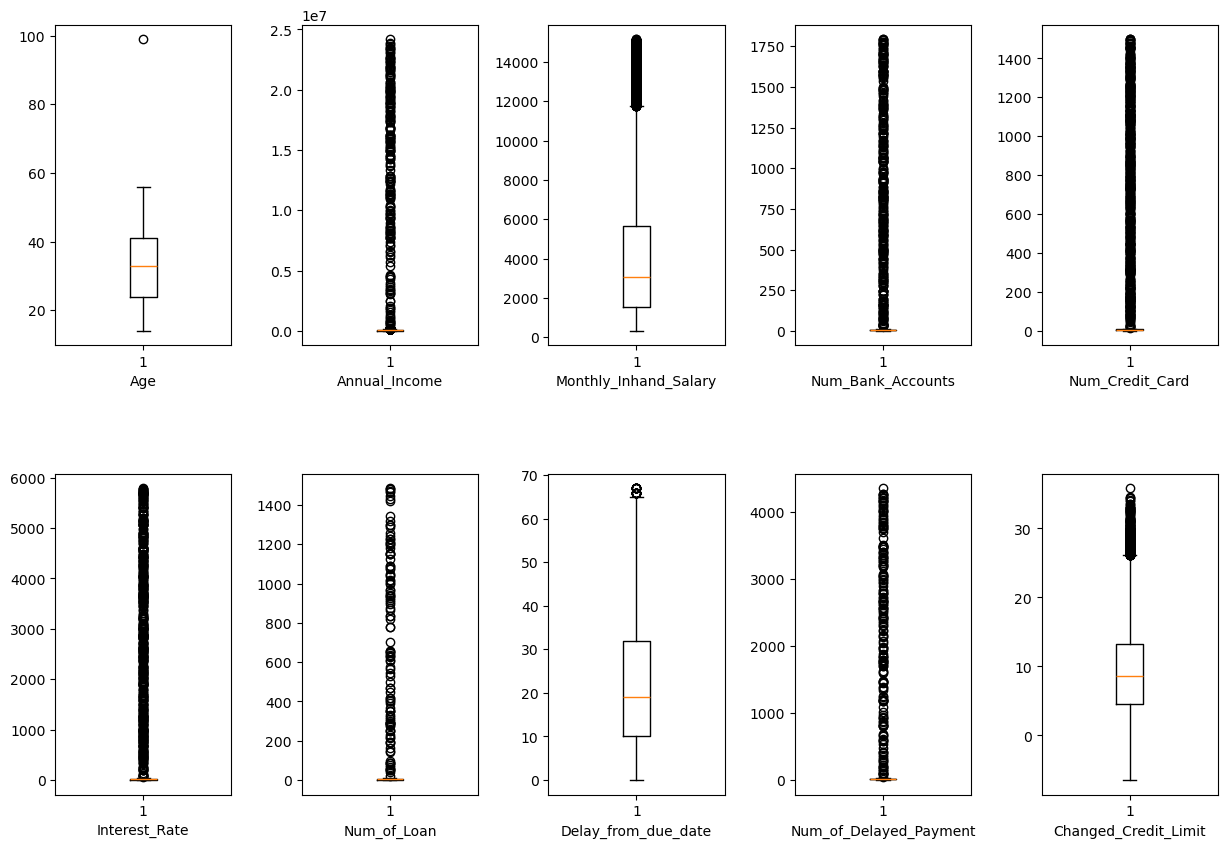

In [47]:
fig, ax = plt.subplots(2,5,figsize=(15,10))
fig.subplots_adjust(hspace=0.4, wspace=0.4)
ax = ax.flatten()

for i, col in enumerate(columns_of_interest):
    ax[i].boxplot(df[col], vert=True)
    ax[i].set_xlabel(col)
plt.savefig('Numeric_Columns_Boxplot.png')
fig

All of these variables (except Age) have lots of outliers. Best approach is to approach them logically. (I will include all the data less than median + 5 times IQR) First I will target the annual income, with those that earn less than $1.5 million per year. The number of bank accounts and credit cards less than 1000. Interest rates are ususally never more than 100%, so will filter these out. The number of loans someone has would rarely exceed 100, and the mean is 7. I'm going to leave Delay_from_due_date, Num_of_Delayed_Payment, and Changed_Credit_Limit  

In [49]:
df['Annual_Income'].std()

1445040.1324529545

In [50]:
df = df[
    (df['Annual_Income'] <= df['Annual_Income'].median() + 5*iqr(df['Annual_Income'])) &
    (df['Num_Bank_Accounts']<= df['Num_Bank_Accounts'].median() + 5*iqr(df['Num_Bank_Accounts'])) &
    (df['Num_Credit_Card']<= df['Num_Credit_Card'].median() + 5*iqr(df['Num_Credit_Card'])) &
    (df['Interest_Rate']<= df['Interest_Rate'].median() + 5*iqr(df['Interest_Rate'])) &
    (df['Num_of_Loan'] <= df['Num_of_Loan'].median() + 5*iqr(df['Num_of_Loan'])) &
    (df['Num_of_Delayed_Payment'] <= df['Num_of_Delayed_Payment'].median() + 5*iqr(df['Num_of_Delayed_Payment'])) &
    (df['Changed_Credit_Limit'] <= df['Changed_Credit_Limit'].median() + 5*iqr(df['Changed_Credit_Limit']))]

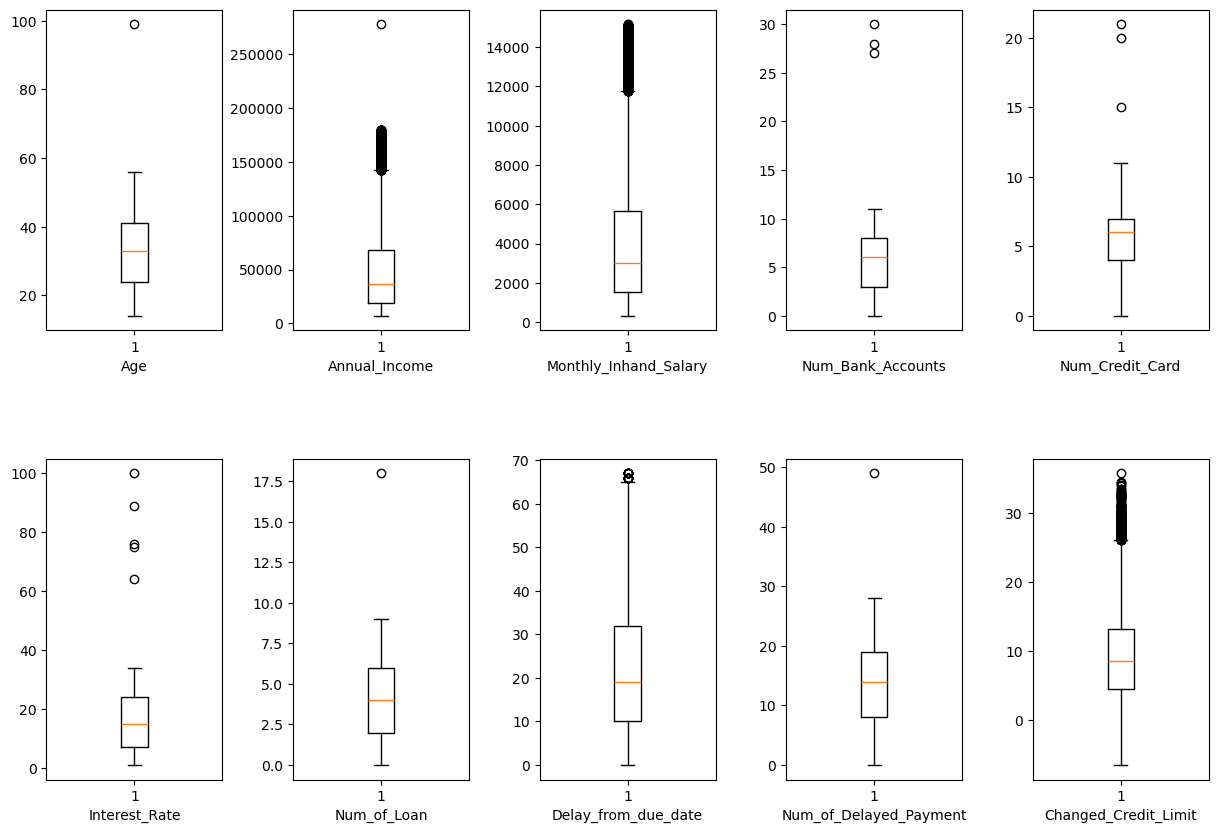

In [51]:
fig, ax = plt.subplots(2,5,figsize=(15,10))
fig.subplots_adjust(hspace=0.4, wspace=0.4)
ax = ax.flatten()

for i, col in enumerate(columns_of_interest):
    ax[i].boxplot(df[col], vert=True)
    ax[i].set_xlabel(col)

fig

In [52]:
column_names = df.columns.tolist()
correlation_matrix = df[column_names].corr()

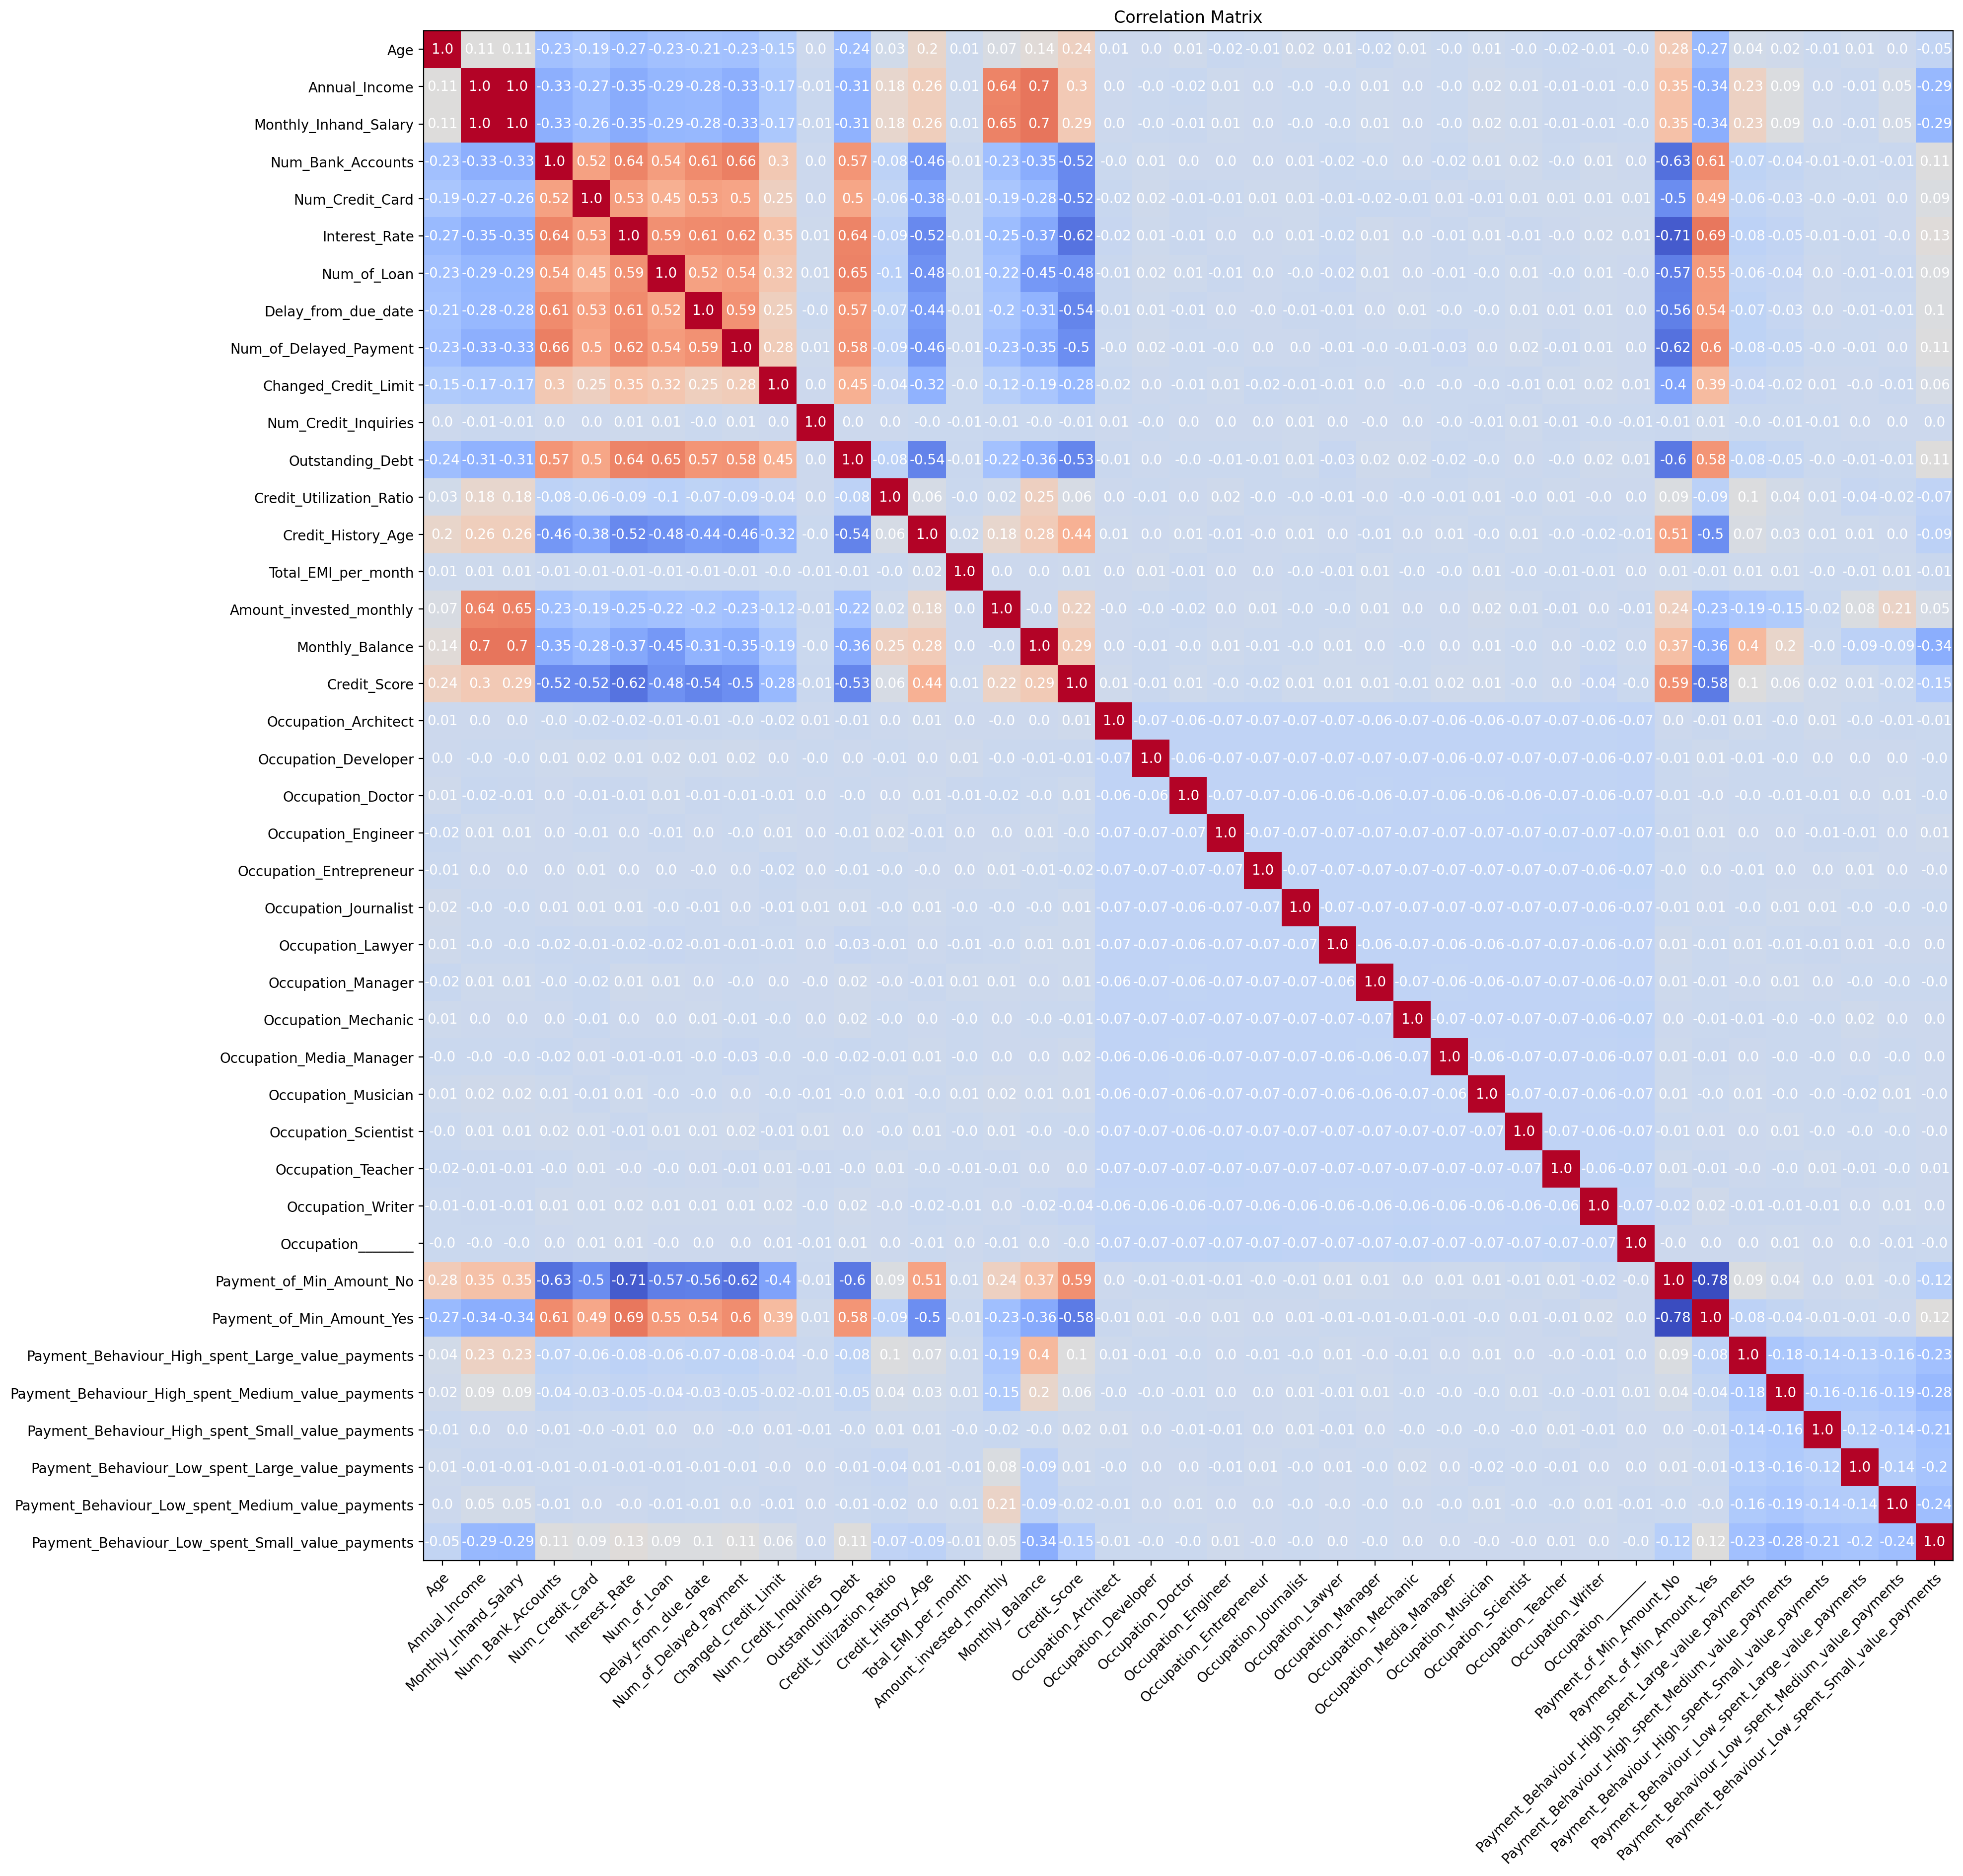

In [53]:
fig, ax = plt.subplots(figsize=(20,20),dpi=200)
im = ax.imshow(correlation_matrix, cmap='coolwarm')

# Show all ticks and label them with the respective list entries
ax.set_xticks(np.arange(len(column_names)), labels= column_names)
ax.set_yticks(np.arange(len(column_names)), labels=column_names)

# Rotate the tick labels and set their alignment.
plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")

# Loop over data dimensions and create text annotations.
for i in range(len(column_names)):
    for j in range(len(column_names)):
        text = ax.text(j, i, round(correlation_matrix.values[i, j], 2),
                       ha="center", va="center", color="w")

ax.set_title("Correlation Matrix")
plt.savefig('Correlation_Matrix.png')
fig

In [54]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
Index: 21740 entries, 0 to 99996
Data columns (total 41 columns):
 #   Column                                              Non-Null Count  Dtype  
---  ------                                              --------------  -----  
 0   Age                                                 21740 non-null  float64
 1   Annual_Income                                       21740 non-null  float64
 2   Monthly_Inhand_Salary                               21740 non-null  float64
 3   Num_Bank_Accounts                                   21740 non-null  int64  
 4   Num_Credit_Card                                     21740 non-null  int64  
 5   Interest_Rate                                       21740 non-null  int64  
 6   Num_of_Loan                                         21740 non-null  float64
 7   Delay_from_due_date                                 21740 non-null  int64  
 8   Num_of_Delayed_Payment                              21740 non-null  float64
 9   

# Analyse: Logistic Regression

***

## Simple Logistic Regression Models

In [58]:
y=df['Credit_Score']

x1 = df[['Monthly_Inhand_Salary']]

x2 = df[['Delay_from_due_date']]

x3= df[['Outstanding_Debt']]

x4= df[['Interest_Rate']]

In [59]:
#LR1

x1_train, x1_test, y1_train, y1_test = train_test_split(x1, y, test_size=0.3)

LR1 = LogisticRegression().fit(x1_train, y1_train)

y1_prediction = LR1.predict(x1_test)

In [60]:
#LR2
x2_train, x2_test, y2_train, y2_test = train_test_split(x2, y, test_size=0.3)

LR2 = LogisticRegression().fit(x2_train, y2_train)

y2_prediction = LR2.predict(x2_test)

In [61]:
#LR3
x3_train, x3_test, y3_train, y3_test = train_test_split(x3, y, test_size=0.3)

LR3 = LogisticRegression().fit(x3_train, y3_train)

y3_prediction = LR3.predict(x3_test)

In [62]:
#LR4
x4_train, x4_test, y4_train, y4_test = train_test_split(x4, y, test_size=0.3)

LR4 = LogisticRegression().fit(x4_train, y4_train)

y4_prediction = LR4.predict(x4_test)

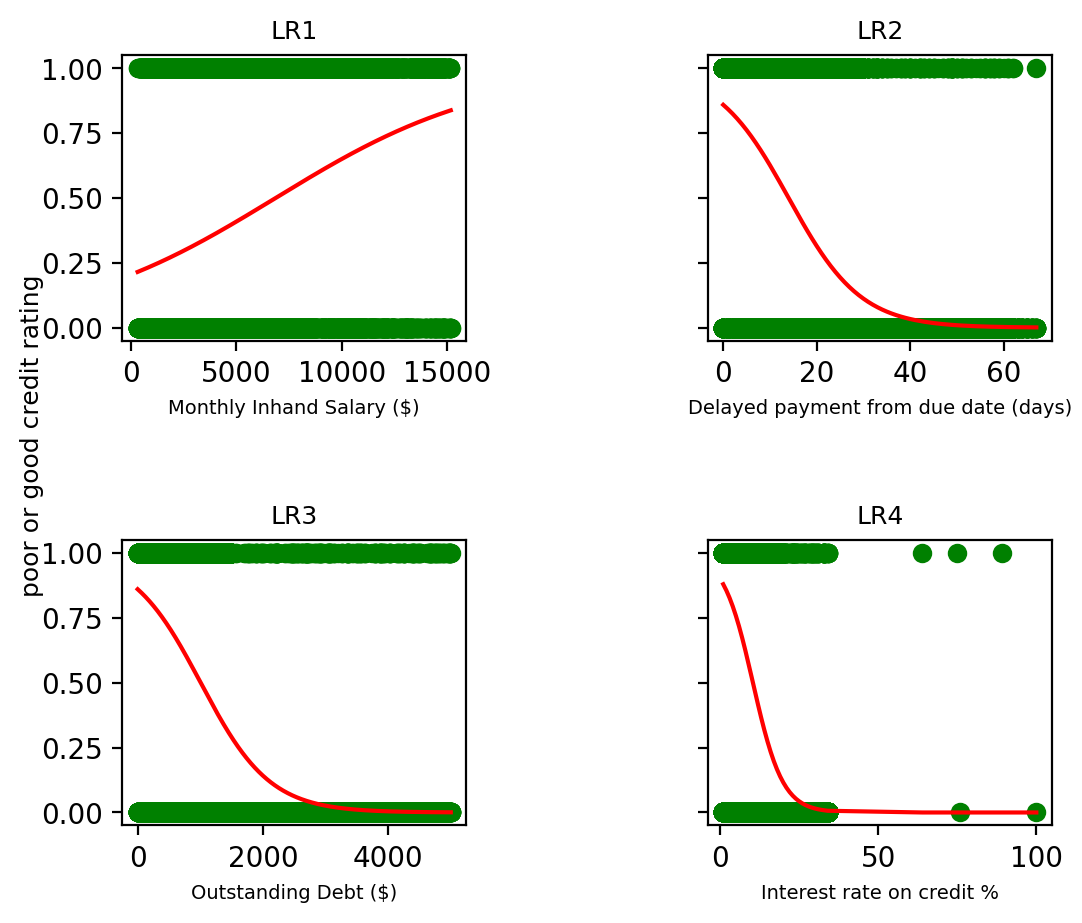

In [63]:
fig , ax = plt.subplots(2,2,figsize=(6,5), sharey='row', dpi=200)
fig.subplots_adjust(hspace=0.7, wspace=0.7)

ax[0,0].scatter(x=df['Monthly_Inhand_Salary'], y=df['Credit_Score'], color='g')
x1_range = df[['Monthly_Inhand_Salary']].sort_values(by='Monthly_Inhand_Salary')
ax[0,0].plot(x1_range, LR1.predict_proba(x1_range)[:,1], color='r')
ax[0,0].set_xlabel('Monthly Inhand Salary ($)',fontsize=7)
ax[0,0].set_title('LR1',fontsize=9)

ax[0,1].scatter(x=df['Delay_from_due_date'], y=df['Credit_Score'], color='g')
x2_range = df[['Delay_from_due_date']].sort_values(by='Delay_from_due_date')
ax[0,1].plot(x2_range, LR2.predict_proba(x2_range)[:,1], color='r')
ax[0,1].set_xlabel('Delayed payment from due date (days)',fontsize=7)
ax[0,1].set_title('LR2',fontsize=9)

ax[1,0].scatter(x=df['Outstanding_Debt'], y=df['Credit_Score'], color='g')
x3_range = df[['Outstanding_Debt']].sort_values(by='Outstanding_Debt')
ax[1,0].plot(x3_range, LR3.predict_proba(x3_range)[:,1], color='r')
ax[1,0].set_xlabel('Outstanding Debt ($)',fontsize=7)
ax[1,0].set_title('LR3',fontsize=9)

ax[1,1].scatter(x=df['Interest_Rate'], y=df['Credit_Score'], color='g')
x4_range = df[['Interest_Rate']].sort_values(by='Interest_Rate')
ax[1,1].plot(x4_range, LR4.predict_proba(x4_range)[:,1], color='r')
ax[1,1].set_xlabel('Interest rate on credit %',fontsize=7)
ax[1,1].set_title('LR4', fontsize=9) 

fig.text(0.04,0.5,'poor or good credit rating',ha='left', va='center', rotation='vertical',fontsize=9)
plt.savefig('Simple_logistic_regressions.png')
fig

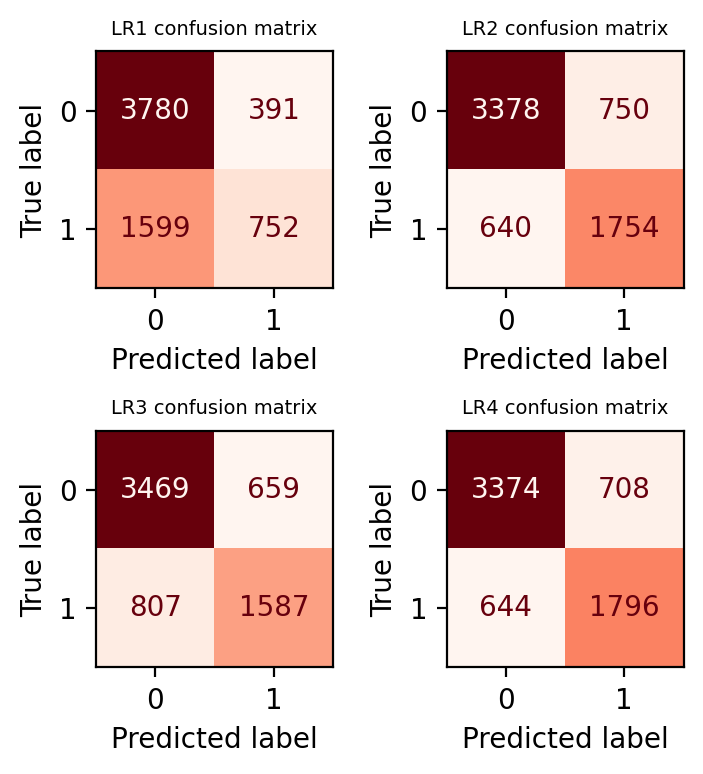

In [64]:
fig , ax = plt.subplots(2,2,figsize=(4,4), dpi=200)
fig.subplots_adjust(hspace=0.6, wspace=0.3)

cm1 = confusion_matrix(y1_test,y1_prediction)
ConfusionMatrixDisplay(cm1, display_labels=LR1.classes_).plot(ax=ax[0,0],cmap='Reds', colorbar=False)
ax[0,0].set_title('LR1 confusion matrix', fontsize=7)

cm2 = confusion_matrix(y2_test,y2_prediction)
ConfusionMatrixDisplay(cm2, display_labels=LR2.classes_).plot(ax=ax[0,1],cmap='Reds', colorbar=False)
ax[0,1].set_title('LR2 confusion matrix', fontsize=7)

cm3 = confusion_matrix(y3_test,y3_prediction)
ConfusionMatrixDisplay(cm3, display_labels=LR3.classes_).plot(ax=ax[1,0],cmap='Reds', colorbar=False)
ax[1,0].set_title('LR3 confusion matrix', fontsize=7)

cm4 = confusion_matrix(y4_test,y4_prediction)
ConfusionMatrixDisplay(cm4, display_labels=LR4.classes_).plot(ax=ax[1,1],cmap='Reds', colorbar=False)
ax[1,1].set_title('LR4 confusion matrix', fontsize=7)

plt.savefig('Simple_logistic_regressions_confusion_matrix.png')
fig

In [65]:
custom_index = ['Accuracy','Precision','Recall','f1_score']

Accuracy = {"LR1":[LR1.score(x1_test,y1_test),metrics.precision_score(y1_test, y1_prediction, average='macro'),metrics.recall_score(y1_test, y1_prediction, average='macro'),metrics.f1_score(y1_test, y1_prediction, average='macro')],
            "LR2":[LR2.score(x2_test,y2_test),metrics.precision_score(y2_test, y2_prediction, average='macro'),metrics.recall_score(y2_test, y2_prediction, average='macro'),metrics.f1_score(y2_test, y2_prediction, average='macro')],
            "LR3":[LR3.score(x3_test,y3_test),metrics.precision_score(y3_test, y3_prediction, average='macro'),metrics.recall_score(y3_test, y3_prediction, average='macro'),metrics.f1_score(y3_test, y3_prediction, average='macro')],
            "LR4":[LR4.score(x4_test,y4_test),metrics.precision_score(y4_test, y4_prediction, average='macro'),metrics.recall_score(y4_test, y4_prediction, average='macro'),metrics.f1_score(y4_test, y4_prediction, average='macro')]}

Accuracy_summary_df = pd.DataFrame(Accuracy, index = custom_index)

Accuracy_summary_df

,LR1,LR2,LR3,LR4
Accuracy,0.694879,0.786875,0.775222,0.792702
Precision,0.680325,0.770598,0.758931,0.778487
Recall,0.613061,0.775489,0.751633,0.781311
f1_score,0.611038,0.772787,0.754805,0.779812


## Complex Logistic Regression Model

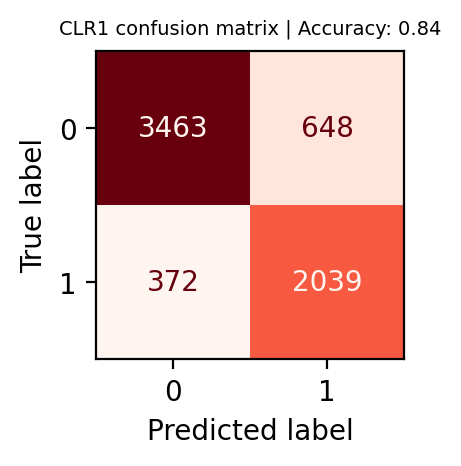

In [67]:
#CLR1

x = df[['Monthly_Inhand_Salary','Delay_from_due_date','Outstanding_Debt','Interest_Rate']]

y = df['Credit_Score']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3)

CLR1 = LogisticRegression().fit(x_train, y_train)

y_prediction = CLR1.predict(x_test)

accuracy = CLR1.score(x_test,y_test)

fig , ax = plt.subplots(figsize=(2,2), dpi=200)

cm = confusion_matrix(y_test,y_prediction)
ConfusionMatrixDisplay(cm, display_labels=CLR1.classes_).plot(ax=ax,cmap='Reds', colorbar=False)
ax.set_title(f'CLR1 confusion matrix | Accuracy: {round(accuracy,2)}', fontsize=7)
plt.savefig('Complex_logistic_regressions_confusion_matrix.png')
fig

In [68]:
print(classification_report(y_test, y_prediction))

              precision    recall  f1-score   support

           0       0.90      0.84      0.87      4111
           1       0.76      0.85      0.80      2411

    accuracy                           0.84      6522
   macro avg       0.83      0.84      0.84      6522
weighted avg       0.85      0.84      0.85      6522



## Super Complex Logistic Regression Model

After using all the ppssible variables at my disposal my inital concerns of perfect collinearity between annul income and monthly inhand salary were proved correct. This made fitting the model unstable and required many iterations that proved too taxing on my laptop. To get round this I tried standardising all variables using the StandardScalar() function from the pre-processing library. The model fitted absered coeficients to the two features, both extreme and opposite to each other e.g. one had a +3 coefficient and the other had -3 coefficient, which is clearly wrong as the coefficients are meant to represent probabilities where the absolute value is between 0 and 1. Therefore, upon careful consideration I decided to remove annual income and keep monthly inhand salary as I felt this would be more accurate at prediciting credit score.

In [71]:
df.drop(['Annual_Income'], axis=1, inplace=True)

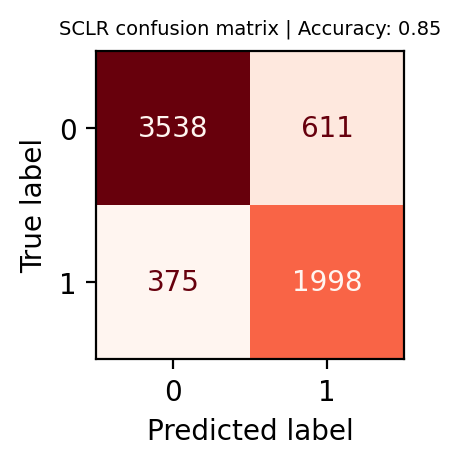

In [72]:
#SCLR

independant_variables = [col for col in df.columns if col != 'Credit_Score']

x = df[independant_variables]

y = df['Credit_Score']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3)

scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

SCLR = LogisticRegression().fit(x_train_scaled, y_train)

y_prediction = SCLR.predict(x_test_scaled)

accuracy = SCLR.score(x_test_scaled,y_test)

fig , ax = plt.subplots(figsize=(2,2), dpi=200)

cm = confusion_matrix(y_test,y_prediction)
ConfusionMatrixDisplay(cm, display_labels=SCLR.classes_).plot(ax=ax,cmap='Reds', colorbar=False)
ax.set_title(f'SCLR confusion matrix | Accuracy: {round(accuracy,2)}', fontsize=7)

fig

In [73]:
print(classification_report(y_test, y_prediction))

              precision    recall  f1-score   support

           0       0.90      0.85      0.88      4149
           1       0.77      0.84      0.80      2373

    accuracy                           0.85      6522
   macro avg       0.83      0.85      0.84      6522
weighted avg       0.85      0.85      0.85      6522



In [74]:
SCLR.coef_

array([[ 9.00149269e-02, -4.80736313e-01,  8.81254604e-02,
        -7.14299752e-01, -7.65901290e-01, -4.86983964e-02,
        -1.02520877e+00,  2.61019952e-01,  9.68327015e-02,
         1.74824776e-04, -4.93101787e-01, -5.07384612e-02,
         1.03415147e-01,  7.92823320e-03,  5.65701537e-01,
         1.07459661e-01,  2.73880852e-02,  8.82929246e-03,
         3.32393029e-03,  1.23489436e-02, -4.40149562e-02,
         6.51666322e-02,  1.98526007e-02,  2.53398135e-02,
        -1.64067851e-03,  5.22480627e-02,  4.21868398e-02,
         5.50414355e-03,  2.66674661e-02, -4.14405678e-02,
         9.60766355e-03,  1.27656702e-01, -3.94413148e-01,
         2.12714113e-01,  1.07780329e-01,  2.71772401e-02,
        -8.86809296e-02, -2.12844146e-01, -4.00863692e-01]])

We added a load of variables but the model accuracy didn't improve the model. This is possibly due to overfitting

## The Best Logistic Regression Model

The last regression contained all the independant variables that were sensibly possible. There were a total of 40 independent variables, however some of them are pretty redundant in prediciting credit score. Therefore, I will now perform Lasso regularisation to reduce the coefficieints of redundant variables.

In [326]:
independant_variables = [col for col in df.columns if col != 'Credit_Score']

In [79]:
C = list(np.logspace(-5,0.5,100))

x = df[independant_variables]

y = df['Credit_Score']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3)

scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

regularisation_dic = {"C":[],
                      "Age": [],
                      "Monthly_Inhand_Salary": [],
                      "Num_Bank_Accounts":[],
                      "Num_Credit_Card":[],
                      "Interest_Rate":[],
                     "Num_of_Loan":[],
                     "Delay_from_due_date":[],
                     "Num_of_Delayed_Payment":[],
                     "Changed_Credit_Limit":[],
                      "Num_Credit_Inquiries":[],
                      "Outstanding_Debt":[],
                      "Credit_Utilization_Ratio":[],
                      "Credit_History_Age": [],
                      "Total_EMI_per_month":[],
                      "Amount_invested_monthly":[],
                      "Monthly_Balance":[],
                      "Occupation_Architect":[],
                      "Occupation_Developer":[],
                      "Occupation_Doctor":[],
                      "Occupation_Engineer":[],
                      "Occupation_Entrepreneur":[],
                      "Occupation_Journalist":[],
                      "Occupation_Lawyer":[],
                      "Occupation_Manager":[],
                      "Occupation_Mechanic":[],
                      "Occupation_Media_Manager":[],
                      "Occupation_Musician":[],
                      "Occupation_Scientist":[],
                      "Occupation_Teacher":[],
                      "Occupation_Writer":[],
                      "Occupation________":[],
                      "Payment_of_Min_Amount_No":[],
                      "Payment_of_Min_Amount_Yes":[],
                      "Payment_Behaviour_High_spent_Large_value_payments":[],
                      "Payment_Behaviour_High_spent_Medium_value_payments":[],
                      "Payment_Behaviour_High_spent_Small_value_payments":[],
                      "Payment_Behaviour_Low_spent_Large_value_payments":[],
                      "Payment_Behaviour_Low_spent_Medium_value_payments":[],
                      "Payment_Behaviour_Low_spent_Small_value_payments":[]}

accuracy_dict = {"C":[], "Accuracy":[]}
                      
for c in C:
    BLR = LogisticRegression(penalty='l1',solver='liblinear', C=c).fit(x_train_scaled, y_train)
    
    regularisation_dic["C"].append(c)
    accuracy_dict["C"].append(c)
    accuracy_dict["Accuracy"].append(BLR.score(x_test_scaled,y_test))
    
    for i, var in enumerate(independant_variables):
        regularisation_dic[var].append(BLR.coef_[0][i])
    
    
                    

In [80]:
accuracy_df = pd.DataFrame(accuracy_dict)
regularisation_df = pd.DataFrame(regularisation_dic)

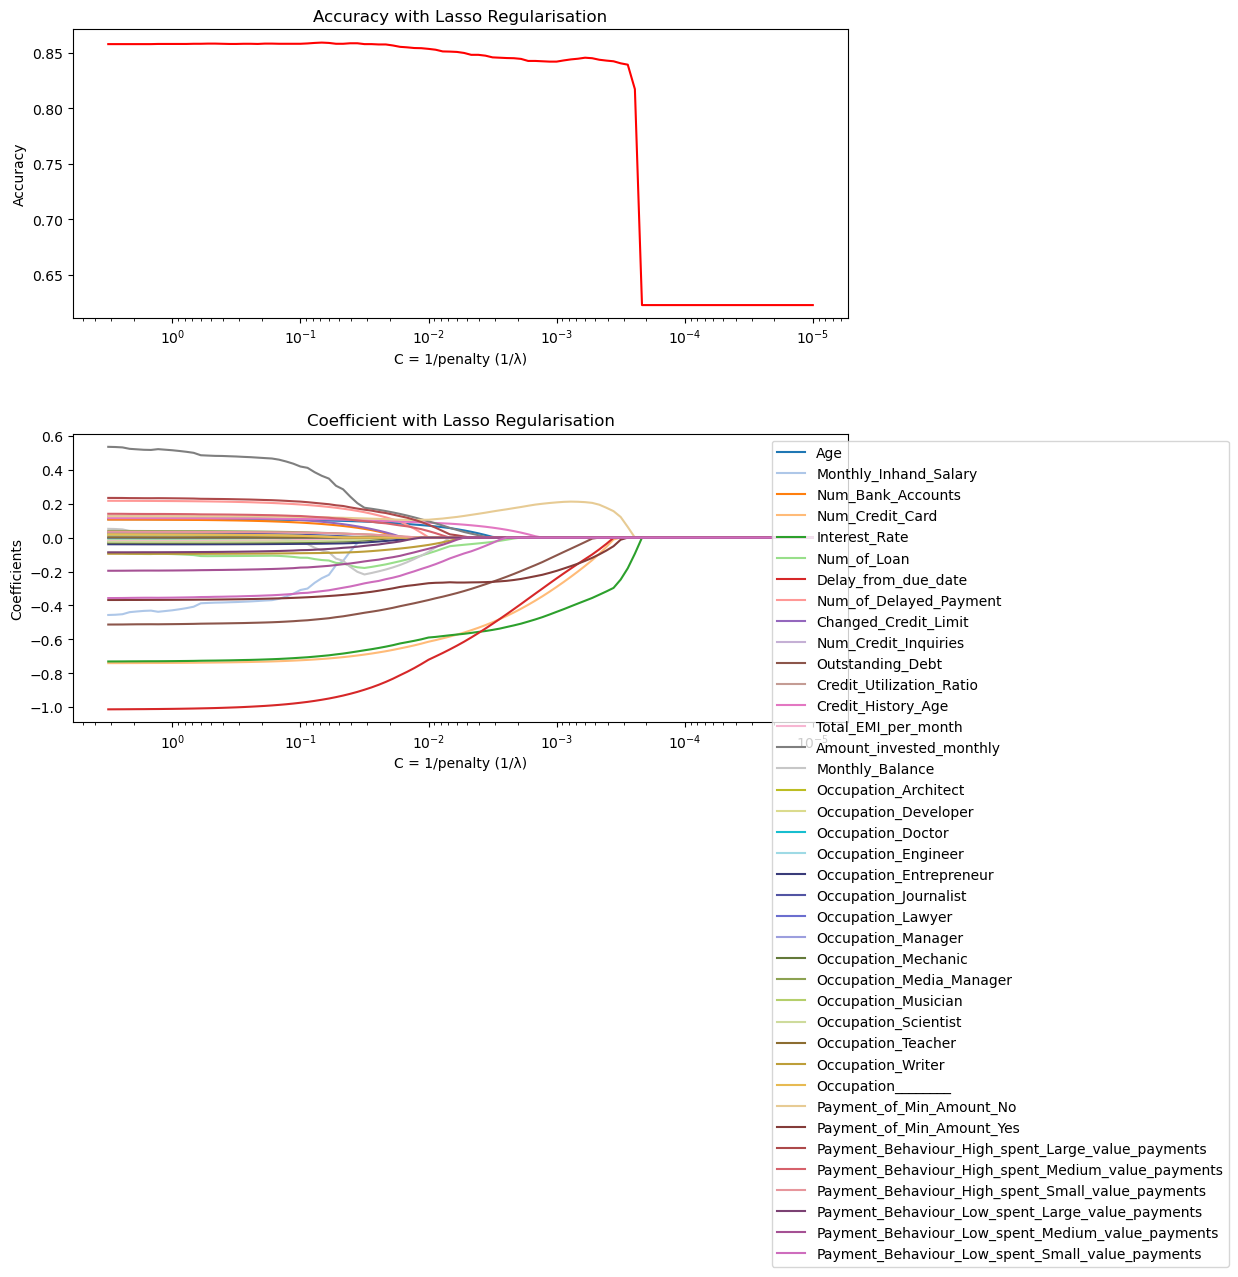

In [81]:
fig, ax = plt.subplots(2,1, figsize=(10,9))
fig.subplots_adjust(hspace=0.4, wspace=0.4)

ax[0].plot(accuracy_df['C'],accuracy_df['Accuracy'], color='red')
ax[0].set_ylabel('Accuracy')
ax[0].set_xlabel('C = 1/penalty (1/λ)')
ax[0].invert_xaxis()
ax[0].set_xscale('log')
ax[0].set_title('Accuracy with Lasso Regularisation')

colors = list(plt.cm.tab20.colors) + list(plt.cm.tab20b.colors) + list(plt.cm.tab20c.colors)

for i, var in enumerate(independant_variables):
    ax[1].plot(regularisation_df['C'],regularisation_df[var], color=colors[i],label=var)

ax[1].set_ylabel('Coefficients')
ax[1].set_xlabel('C = 1/penalty (1/λ)')
ax[1].invert_xaxis()
ax[1].set_xscale('log')
ax[1].legend(loc="upper right",bbox_to_anchor=(1.5,1))
ax[1].set_title('Coefficient with Lasso Regularisation')

fig

In [82]:
print(regularisation_df.describe())

                C         Age  Monthly_Inhand_Salary  Num_Bank_Accounts  \
count  100.000000  100.000000             100.000000         100.000000   
mean     0.263352    0.049928              -0.126086           0.036067   
std      0.614341    0.049327               0.180491           0.046090   
min      0.000010    0.000000              -0.456508           0.000000   
25%      0.000237    0.000000              -0.350764           0.000000   
50%      0.005635    0.046003               0.000000           0.000000   
75%      0.133561    0.104978               0.000000           0.093004   
max      3.162278    0.108531               0.000000           0.106115   

       Num_Credit_Card  Interest_Rate  Num_of_Loan  Delay_from_due_date  \
count       100.000000     100.000000   100.000000           100.000000   
mean         -0.425385      -0.450430    -0.059001            -0.534136   
std           0.315387       0.291717     0.059354             0.428724   
min          -0.740572  

One of the major issues and one of the reasons I had to standardise the features was due to the perfect correlation of annual income and monthly in hand salary. Given monthly inhand salary has a larger coefficient and likely to be better at determining credit score I will drop annual income from the model and try and hone in on inportant features.

In [84]:
important_variables = ['Monthly_Inhand_Salary','Outstanding_Debt','Num_Credit_Card','Interest_Rate','Num_of_Delayed_Payment','Delay_from_due_date','Payment_of_Min_Amount_No','Payment_of_Min_Amount_Yes',
                       'Payment_Behaviour_High_spent_Large_value_payments','Payment_Behaviour_High_spent_Medium_value_payments',
                       'Payment_Behaviour_High_spent_Small_value_payments','Payment_Behaviour_Low_spent_Small_value_payments',
                       'Payment_Behaviour_Low_spent_Medium_value_payments','Payment_Behaviour_Low_spent_Large_value_payments']


In [85]:
C = list(np.logspace(-5,1,100))

x = df[important_variables]

y = df['Credit_Score']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3)

regularisation_dic = {"C":[],
                      **{var: [] for var in important_variables}}

accuracy_dict = {"C":[], "Accuracy":[]}
                      
for c in C:
    BLR = LogisticRegression(penalty='l1',solver='liblinear', C=c).fit(x_train, y_train)
    
    regularisation_dic["C"].append(c)
    accuracy_dict["C"].append(c)
    accuracy_dict["Accuracy"].append(BLR.score(x_test,y_test))
    
    for i, var in enumerate(important_variables):
        regularisation_dic[var].append(BLR.coef_[0][i])
    
    
                    

In [86]:
accuracy_df = pd.DataFrame(accuracy_dict)
regularisation_df = pd.DataFrame(regularisation_dic)

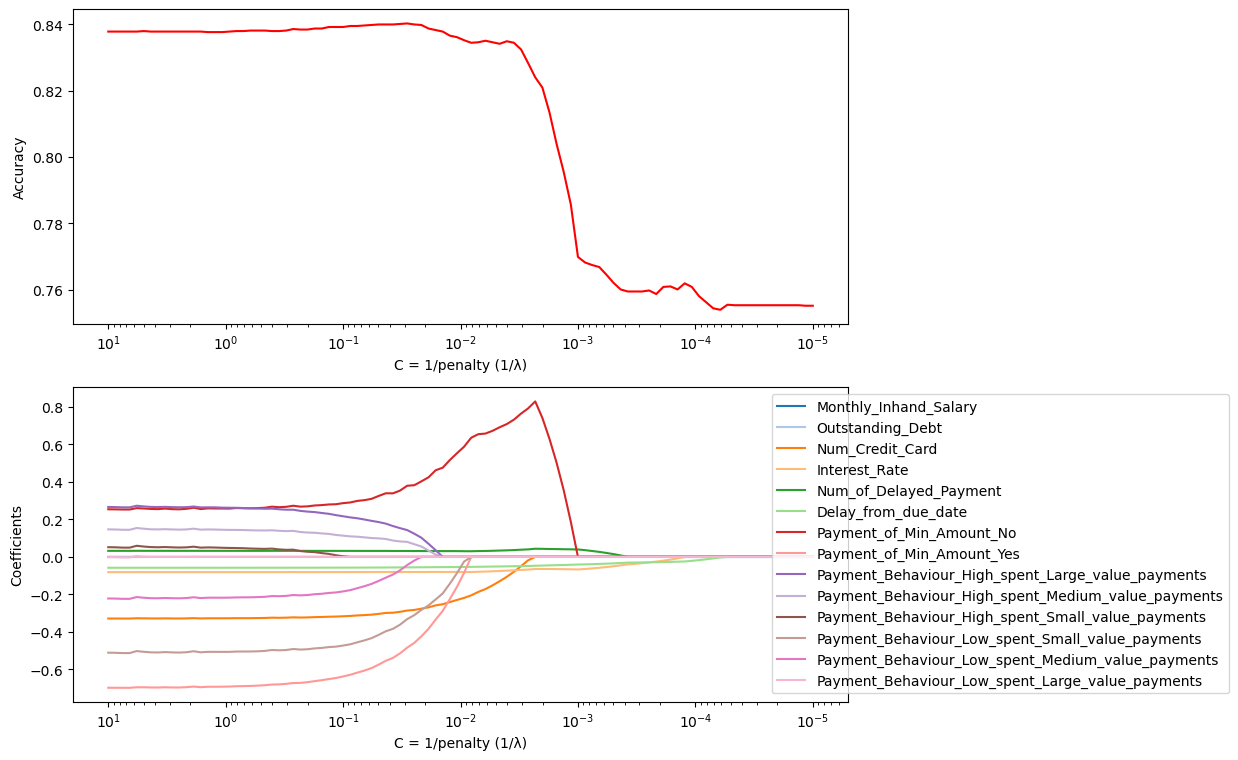

In [87]:
fig, ax = plt.subplots(2,1, figsize=(10,9))

ax[0].plot(accuracy_df['C'],accuracy_df['Accuracy'], color='red')
ax[0].set_ylabel('Accuracy')
ax[0].set_xlabel('C = 1/penalty (1/λ)')
ax[0].set_xscale('log')
ax[0].invert_xaxis()
colors = list(plt.cm.tab20.colors) + list(plt.cm.tab20b.colors) + list(plt.cm.tab20c.colors)

for i, var in enumerate(important_variables):
    ax[1].plot(regularisation_df['C'],regularisation_df[var], color=colors[i],label=var)

ax[1].set_ylabel('Coefficients')
ax[1].set_xlabel('C = 1/penalty (1/λ)')
ax[1].set_xscale('log')
ax[1].invert_xaxis()
ax[1].legend(loc="upper right",bbox_to_anchor=(1.5,1))

fig

What is the optimal value of C and what are the best explanatory varibales to have in the model?

## Cross Validation: Tuning the model

This is a measure to prevent data leakage when trying to fine tune the model. I have been running the logistic model over and over again including different variables which means there is a high chance of data leakage and overfitting the model. Cross validation can prevent this. It works by instead of splitting the x and y data in train and test sets, it splits the train data up into multiple sets or typically 4-5 folds (k-1 fold). One fold is kept as a test set to test the model that has been trained on multiple train data sets. You can then assess whether the model is generalisable by looking at the distribution of of the model's performance metrics. You can also determine the optimal hyperparamters (the penalty for regularisation) and optimal features for the model by comparing model performance scores.

In [328]:
C = list(np.logspace(-5,0.5,100))

param_grid = {'C': C}

x = df[independant_variables]

y = df['Credit_Score']

x_train,x_test,y_train,y_test = train_test_split(x,y, test_size=0.3) # initial split

scaler = StandardScaler() #standardising features

x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

LR = LogisticRegression(penalty='l1', solver='liblinear')

grid_search = GridSearchCV(
    estimator=LR,
    param_grid=param_grid,
    scoring='accuracy', #optimising accurcay while changing C
    cv=3, #Number of folds, the train 
    verbose=1 #prints progress during fitting
)

grid_search.fit(x_train_scaled, y_train)

print('Best C', grid_search.best_params_['C'])
print('Best cross-validation accuracy:', grid_search.best_score_)

Fitting 3 folds for each of 100 candidates, totalling 300 fits
Best C 0.24484367468222243
Best cross-validation accuracy: 0.8476146784807219


Now that we have our optimal penalty, we can determine the most important features to incliude in our model

In [165]:
best_c = grid_search.best_params_['C']

In [330]:
x = df[independant_variables]

y = df['Credit_Score']

x_train,x_test,y_train,y_test = train_test_split(x,y, test_size=0.3) # initial split

scaler = StandardScaler() #standardising features

x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

LR = LogisticRegression(penalty='l1', solver='liblinear', C=best_c).fit(x_train_scaled,y_train)

feature_importance = LR.coef_[0]
feature_names = x_train.columns

important_features = [(name, coef) for name, coef in zip(feature_names, feature_importance) if coef !=0]



In [332]:
important_features = sorted(important_features, key=lambda x:x[1], reverse=True)

important_features

[('Amount_invested_monthly', 0.49613259212831384),
 ('Payment_Behaviour_High_spent_Large_value_payments', 0.2782142893418827),
 ('Num_of_Delayed_Payment', 0.21338786229103146),
 ('Changed_Credit_Limit', 0.12422078426631156),
 ('Payment_Behaviour_High_spent_Medium_value_payments', 0.12029097274864119),
 ('Credit_History_Age', 0.10773121180626825),
 ('Payment_of_Min_Amount_No', 0.07880590380691961),
 ('Num_Bank_Accounts', 0.07824890420309395),
 ('Occupation_Journalist', 0.07532358862133724),
 ('Age', 0.07221824048798076),
 ('Occupation_Media_Manager', 0.06180205237389893),
 ('Payment_Behaviour_High_spent_Small_value_payments', 0.030639260312634777),
 ('Occupation_Manager', 0.024831560524497483),
 ('Occupation_Musician', 0.017688772403784837),
 ('Monthly_Balance', 0.010805027986343968),
 ('Occupation_Lawyer', 0.010406735634598662),
 ('Occupation_Teacher', 0.009953430011082395),
 ('Occupation_Engineer', -0.0017416773959241466),
 ('Occupation_Architect', -0.006612493699937739),
 ('Occupatio

This sorted list of features by the absolute value of their coefficents shows which features are most important to the model in determining credit score. The larger the coefficient the stronger its contribution in determining the credit score. It appears that payment behviour is critical to determining an individuals credit score, along with payment of the minimum amount and number of credit cards. The model also shows that some occupations have a considerable role in determining credit score, particularly being a writer, journalist, entrepreneur. Some other honourable mentions are Interest_Rate,Delay_from_due_date, Num_of_Loan and Num_of_Delayed_Payment.

Another way we could select features of our model is perform hypothesis testing on the coefficients of the model to see whether they are significant. However this requires another model/library... (Chat GPT: promtp - x = df[independant_variables]

y = df['Credit_Score']

x_train,x_test,y_train,y_test = train_test_split(x,y, test_size=0.3) # initial split

LR = LogisticRegression(penalty='l1', solver='liblinear', C=best_c).fit(x_train,y_train)

feature_importance = abs(LR.coef_[0])
feature_names = x_train.columns

important_features = [(name, coef) for name, coef in zip(feature_names, feature_importance) if coef !=0 is there a way to incorporate calculating the p-value of all the calculated coefficients and storing them in a list)

In [170]:
import statsmodels.api as sm

X = x_train
Y = y_train

X = sm.add_constant(X)

logit_model = sm.Logit(Y,X).fit()

coefficients = round(logit_model.params, 4)

p_values = round(logit_model.pvalues, 4)

feature_names = X.columns
important_features = [
    (name, coef, pval) for name, coef, pval in zip(feature_names, coefficients, p_values) if coef != 0
]

sorted_important_features = sorted(important_features, key=lambda x: abs(x[1]), reverse=True)

for name, coef, pval in sorted_important_features:
                                   print(f"{name}: coefficient = {coef}, P-value = {pval}")
                                   

Optimization terminated successfully.
         Current function value: 0.334464
         Iterations 8
const: coefficient = 2.9905, P-value = 0.0
Payment_Behaviour_Low_spent_Small_value_payments: coefficient = -0.8777, P-value = 0.0
Payment_Behaviour_High_spent_Large_value_payments: coefficient = 0.7941, P-value = 0.0
Payment_of_Min_Amount_Yes: coefficient = -0.7199, P-value = 0.0
Payment_Behaviour_Low_spent_Medium_value_payments: coefficient = -0.6171, P-value = 0.0
Occupation_Journalist: coefficient = 0.3325, P-value = 0.0152
Payment_Behaviour_Low_spent_Large_value_payments: coefficient = -0.3271, P-value = 0.0059
Occupation_Writer: coefficient = -0.325, P-value = 0.0226
Num_Credit_Card: coefficient = -0.3176, P-value = 0.0
Payment_Behaviour_High_spent_Medium_value_payments: coefficient = 0.2974, P-value = 0.0064
Payment_of_Min_Amount_No: coefficient = 0.2206, P-value = 0.0054
Occupation_Musician: coefficient = 0.2112, P-value = 0.1384
Occupation_Teacher: coefficient = 0.2104, P-value

Here we can see that Occupation is actually not a significant determinant of credit score. Therefore, I will not include Occupation in my final model.

Annoyingly, some payment behaviours have significant coefficeints and 2 have insignificant coefficients. I have decided to keep them all in as dropping two dummy variables out of the possible 6 will make them difficult to interpret.

Surprisingly, monthly_inhand_salary has little effect on credit score as initally thought as it has a coefficient close to zero and is. Interestingly when I ran this model with annual income instead of monthly inhand salary its coefficient was approximately zero and was filtered out of the results. This might sugest that tax brackets can play some minor role in explaining credit score? Monthly salary is still significant and given the ask was to include income I will include it in the iportant features

In [621]:
final_features = ['Monthly_Inhand_Salary','Outstanding_Debt','Num_Credit_Card','Interest_Rate','Num_of_Delayed_Payment','Delay_from_due_date','Num_of_Loan',
                  'Payment_of_Min_Amount_No','Payment_of_Min_Amount_Yes',
                       'Payment_Behaviour_High_spent_Large_value_payments','Payment_Behaviour_High_spent_Medium_value_payments',
                       'Payment_Behaviour_High_spent_Small_value_payments','Payment_Behaviour_Low_spent_Small_value_payments',
                       'Payment_Behaviour_Low_spent_Medium_value_payments','Payment_Behaviour_Low_spent_Large_value_payments']


Given that we have identified the key features it makes sense to use a ridge regularisation to penalise large coefficients but not reduce them to zero as we have deemed them all important in determining credit score

In [336]:
C = list(np.logspace(-5,1,100))

param_grid = {'C': C}

x = df[final_features]

y = df['Credit_Score']

x_train,x_test,y_train,y_test = train_test_split(x,y, test_size=0.3) # initial split

LR = LogisticRegression(penalty='l2', solver='liblinear')

grid_search = GridSearchCV(
    estimator=LR,
    param_grid=param_grid,
    scoring='accuracy', #optimising accurcay while changing C
    cv=5, #Number of folds, the train 
    verbose=1 #prints progress during fitting
)

grid_search.fit(x_train, y_train)

#ChatGPT helped with cross validation methods

print('Best C', grid_search.best_params_['C'])
print('Best cross-validation accuracy:', round(grid_search.best_score_,4))
print('Mean accuracy:', grid_search.cv_results_['mean_test_score'].mean().round(4))
print('Standard Deviation of Models accuracy:', grid_search.cv_results_['std_test_score'].mean().round(4))

Fitting 5 folds for each of 100 candidates, totalling 500 fits
Best C 0.35111917342151344
Best cross-validation accuracy: 0.841
Mean accuracy: 0.8181
Standard Deviation of Models accuracy: 0.0074


## The very best model

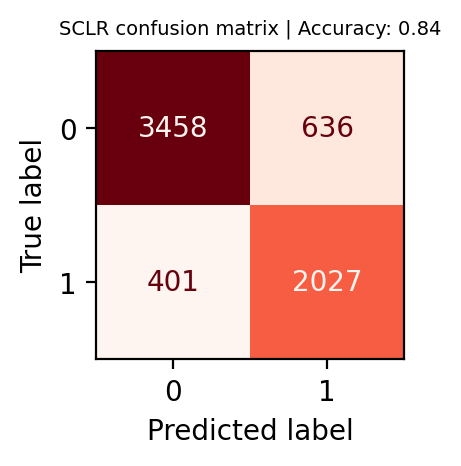

In [178]:
#VBLR

#x = df[final_features]

#y = df['Credit_Score']

#x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3)

VBLR = LogisticRegression(penalty='l2', solver='liblinear',C=grid_search.best_params_['C']).fit(x_train, y_train)

y_prediction = VBLR.predict(x_test)

accuracy = VBLR.score(x_test,y_test)

fig , ax = plt.subplots(figsize=(2,2), dpi=200)

cm = confusion_matrix(y_test,y_prediction)
ConfusionMatrixDisplay(cm, display_labels=VBLR.classes_).plot(ax=ax,cmap='Reds', colorbar=False)
ax.set_title(f'SCLR confusion matrix | Accuracy: {round(accuracy,2)}', fontsize=7)
plt.savefig('Best_logistic_regressions_confusion_matrix.png')
fig

In [179]:
print(classification_report(y_test, y_prediction))

              precision    recall  f1-score   support

           0       0.90      0.84      0.87      4094
           1       0.76      0.83      0.80      2428

    accuracy                           0.84      6522
   macro avg       0.83      0.84      0.83      6522
weighted avg       0.85      0.84      0.84      6522



## Prediction:

In [181]:
my_details = {"Monthly_Inhand_Salary":1913,
              "Outstanding_Debt": 48189.49,
              "Num_Credit_Card": 0,
              "Interest_Rate": 5,
              "Num_of_Delayed_Payment":0,
              "Delay_from_due_date": 0,
              "Num_of_Loan": 1,
              "Payment_of_Min_Amount_No":0,
              "Payment_of_Min_Amount_Yes":0,
              "Payment_Behaviour_High_spent_Large_value_payments":0,
              "Payment_Behaviour_High_spent_Medium_value_payments":0,
              "Payment_Behaviour_High_spent_Small_value_payments":1,
              "Payment_Behaviour_Low_spent_Small_value_payments":0,
              "Payment_Behaviour_Low_spent_Medium_value_payments":0,
              "Payment_Behaviour_Low_spent_Large_value_payments":0}

In [182]:
input_data = pd.DataFrame([my_details])

In [183]:
prediction = VBLR.predict(input_data)
prediction_probability = VBLR.predict_proba(input_data)

print(f"Prediction credit score class: {prediction[0]}")
print(f"Prediction credit score class probability: {prediction_probability[0].round(2)}")

Prediction credit score class: 0
Prediction credit score class probability: [1. 0.]


### Precision-Recall Curve
Trade-off between precision and recall for a binary classification model across different thresholds of predicitive probabilities. How well the model balances false positives (precision) and false negatives (recall) when deciding whetehr a given instance belongs to the positive class.

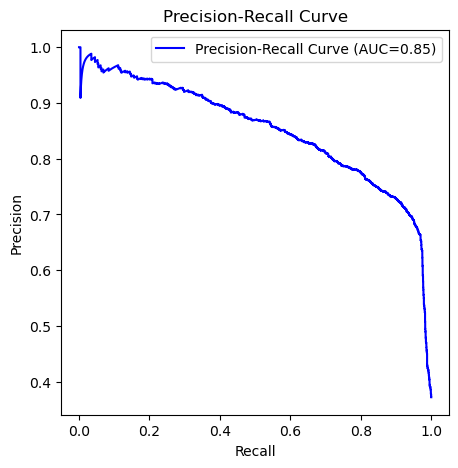

In [649]:
from sklearn.metrics import precision_recall_curve, auc, PrecisionRecallDisplay

y_probs = VBLR.predict_proba(x_test)[:,1] #probabilities of positive class (good)

precision, recall, thresholds = precision_recall_curve(y_test,y_probs) #calculates precision, recall and threshold of classifier

precision_recall_auc = auc(recall, precision) # area under the curve

fig, ax = plt.subplots(1,1,figsize=(5,5))

ax.plot(recall, precision, label = f'Precision-Recall Curve (AUC={precision_recall_auc:.2f})', color='blue')
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Precision-Recall Curve')
ax.legend()
plt.savefig('Precision-Recall Curve.png')
fig

### Receiver Operating Characteristic (ROC) Curve 
The trade off between the True Positive Rate (recall) anf the False Positive Rate at different probability thresholds

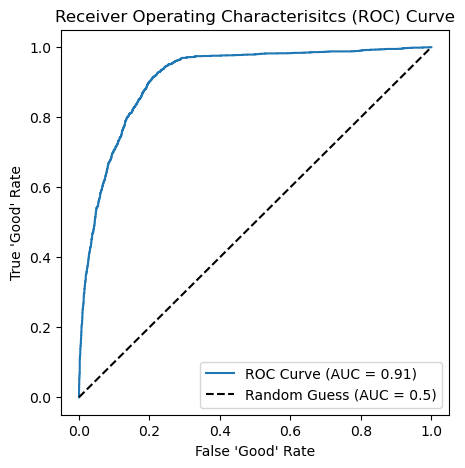

In [651]:
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr , thresholds = roc_curve(y_test, y_probs) # calucates FPR, TPR at different thresholds

roc_auc = roc_auc_score(y_test, y_probs) # calculates area under the curve

fig, ax = plt.subplots(1,1, figsize=(5,5))

ax.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.2f})')
ax.plot([0,1],[0,1], 'k--', label='Random Guess (AUC = 0.5)') # diagonal line to represent when a classifier is just guesses 50/50
ax.set_xlabel("False 'Good' Rate")
ax.set_ylabel("True 'Good' Rate")
ax.set_title('Receiver Operating Characterisitcs (ROC) Curve')
ax.legend()
plt.savefig('ROC Curve.png')
fig

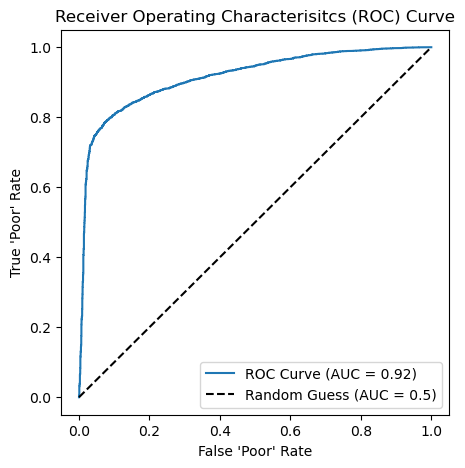

In [653]:
x = df[final_features]

y = df['Credit_Score']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3)

y_probs_poor = VBLR.predict_proba(x_test)[:,0] #probabilities of poor class 

tpr, fpr, thresholds = roc_curve(y_test, y_probs_poor) # calucates FNR, TNR at different thresholds

roc_auc = roc_auc_score(y_test, y_probs_poor) # calculates area under the curve

fig, ax = plt.subplots(1,1, figsize=(5,5))

ax.plot(fpr,tpr,label=f'ROC Curve (AUC = {1-roc_auc:.2f})')
ax.plot([0,1],[0,1], 'k--', label='Random Guess (AUC = 0.5)') # diagonal line to represent when a classifier is just guesses 50/50
ax.set_xlabel("False 'Poor' Rate")
ax.set_ylabel("True 'Poor' Rate")
ax.set_title('Receiver Operating Characterisitcs (ROC) Curve')
ax.legend()
plt.savefig('ROC negative Curve.png')
fig

In [625]:
print(VBLR.classes_)

[0 1]


In [639]:
VBLR.predict_proba(x_test)[0,:]

array([0.99207045, 0.00792955])

In [635]:
VBLR.predict_proba(x_test)[:,0]

array([0.99207045, 0.99398022, 0.08900269, ..., 0.99620459, 0.68709452,
       0.9507026 ])

# Analyse: Perceptron

Using the final features highlighted by our analysis using logistic regression I will implement a Perceptron ML model to predict credit score...

In [350]:
independant_variables = [col for col in df.columns if col != 'Credit_Score']

x = df[independant_variables]
y = df['Credit_Score']
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3)

In [191]:
param_grid = {
    "eta0": list(np.logspace(-3,1,4)),
    "max_iter":list(range(100,1000,4)),
    "tol":list(np.logspace(-4,0,4)),
    "alpha": list(np.logspace(-4,0,4))
}

grid_search = GridSearchCV(estimator=Perceptron(penalty='l1',fit_intercept=True), param_grid=param_grid, scoring='accuracy',cv=2)
grid_search.fit(x_train,y_train)

print('Best Hyperparameters:', grid_search.best_params_)
print('Best Model Accuracy:', grid_search.best_score_)

Best Hyperparameters: {'alpha': 0.002154434690031882, 'eta0': 0.001, 'max_iter': 100, 'tol': 0.0001}
Best Model Accuracy: 0.7621238007622553


In [352]:
Percep = Perceptron(penalty='l1',alpha=0.002154434690031882, eta0=0.001,max_iter=100, tol=0.0001,fit_intercept=True).fit(x_train, y_train)

y_prediction = Percep.predict(x_test)

accuracy = Percep.score(x_test,y_test)

In [354]:
print(classification_report(y_test, y_prediction))

              precision    recall  f1-score   support

           0       0.88      0.81      0.84      4129
           1       0.71      0.80      0.76      2393

    accuracy                           0.81      6522
   macro avg       0.79      0.81      0.80      6522
weighted avg       0.82      0.81      0.81      6522



In [194]:
feature_importance = pd.DataFrame(Percep.coef_[0], index=x.columns, columns=['Weight'])

In [195]:
feature_importance.sort_values(by='Weight', ascending=False)

,Weight
Amount_invested_monthly,59.990421
Monthly_Balance,54.716682
Credit_History_Age,33.795692
Age,29.342692
Payment_of_Min_Amount_No,2.717692
Credit_Utilization_Ratio,1.863612
Total_EMI_per_month,1.658359
Payment_Behaviour_High_spent_Large_value_payments,0.468692
Payment_Behaviour_High_spent_Medium_value_payments,0.364692
Payment_Behaviour_High_spent_Small_value_payments,0.180692


In [342]:
important_features = ['Amount_invested_monthly','Monthly_Balance','Credit_History_Age','Age','Payment_of_Min_Amount_No',
                      'Payment_Behaviour_High_spent_Large_value_payments','Payment_Behaviour_High_spent_Medium_value_payments',
                      'Payment_Behaviour_High_spent_Small_value_payments','Occupation_Journalist',
                      'Payment_Behaviour_Low_spent_Large_value_payments','Occupation_Doctor','Occupation_Manager','Occupation_Entrepreneur',
                      'Occupation_Writer','Payment_Behaviour_Low_spent_Medium_value_payments',
                      'Payment_Behaviour_Low_spent_Small_value_payments','Monthly_Inhand_Salary','Credit_Utilization_Ratio',
                      'Num_Credit_Inquiries','Payment_of_Min_Amount_Yes','Num_of_Loan','Num_Bank_Accounts','Changed_Credit_Limit',
                      'Outstanding_Debt','Num_Credit_Card','Total_EMI_per_month','Num_of_Delayed_Payment','Interest_Rate',
                      'Delay_from_due_date']

In [344]:
x = df[important_features]
y = df['Credit_Score']
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3)

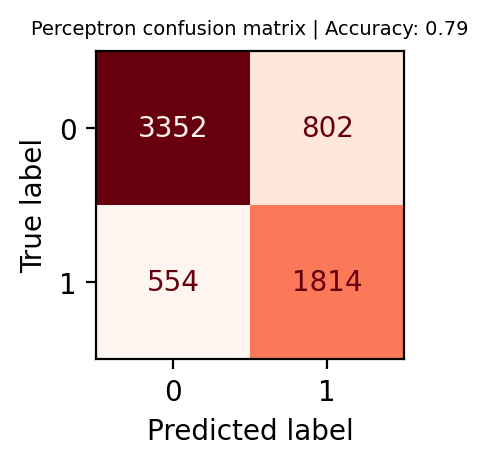

In [346]:
Perceptron1 = Perceptron(alpha=0.001, eta0=0.1,max_iter=500, tol=0.0001,fit_intercept=True).fit(x_train, y_train)

y_prediction = Perceptron1.predict(x_test)

accuracy = Perceptron1.score(x_test,y_test)

fig , ax = plt.subplots(figsize=(2,2), dpi=200)

cm = confusion_matrix(y_test,y_prediction)
ConfusionMatrixDisplay(cm, display_labels=Perceptron1.classes_).plot(ax=ax,cmap='Reds', colorbar=False)
ax.set_title(f'Perceptron confusion matrix | Accuracy: {round(accuracy,2)}', fontsize=7)

fig

In [348]:
print(classification_report(y_test, y_prediction))

              precision    recall  f1-score   support

           0       0.86      0.81      0.83      4154
           1       0.69      0.77      0.73      2368

    accuracy                           0.79      6522
   macro avg       0.78      0.79      0.78      6522
weighted avg       0.80      0.79      0.79      6522



## Prediction

In [200]:
my_details = {'Amount_invested_monthly':200,'Monthly_Balance':500,'Credit_History_Age':0,'Age':24,'Payment_of_Min_Amount_No':0,
                      'Payment_Behaviour_High_spent_Large_value_payments':0,'Payment_Behaviour_High_spent_Medium_value_payments':0,
                      'Payment_Behaviour_High_spent_Small_value_payments':1,'Occupation_Journalist':0,
                      'Payment_Behaviour_Low_spent_Large_value_payments':0,'Occupation_Doctor':0,'Occupation_Manager':0,'Occupation_Entrepreneur':0,
                      'Occupation_Writer':0,'Payment_Behaviour_Low_spent_Medium_value_payments':0,
                      'Payment_Behaviour_Low_spent_Small_value_payments':0,'Monthly_Inhand_Salary':1913,'Credit_Utilization_Ratio':0,
                      'Num_Credit_Inquiries':0,'Payment_of_Min_Amount_Yes':0,'Num_of_Loan':1,'Num_Bank_Accounts':4,'Changed_Credit_Limit':0,
                      'Outstanding_Debt':48189.49,'Num_Credit_Card':0,'Total_EMI_per_month':0,'Num_of_Delayed_Payment':0,'Interest_Rate':5,
                      'Delay_from_due_date':0}
input_data = pd.DataFrame([my_details])

In [201]:
prediction = Perceptron1.predict(input_data)

print(f"Prediction credit score class: {prediction[0]}")

Prediction credit score class: 0


# Decision Tree Classifier

In [469]:
test_df = pd.read_csv('Kaggle/test.csv')
train_df = pd.read_csv('Kaggle/train.csv')
df1 = pd.concat([train_df, test_df], ignore_index=True)
df1.drop(['Name','Month','SSN','ID','Customer_ID','Credit_Mix','Type_of_Loan'], axis=1, inplace=True)
df1.dropna(subset=['Credit_Score'], inplace=True)

/var/folders/c7/s_7n84_s6g92fqcd6c0jf1nh0000gn/T/ipykernel_17268/751085701.py:2: DtypeWarning: Columns (26) have mixed types. Specify dtype option on import or set low_memory=False.
  train_df = pd.read_csv('Kaggle/train.csv')


In [471]:
columns_convert_num = ['Age','Num_of_Loan','Num_of_Delayed_Payment','Changed_Credit_Limit','Outstanding_Debt','Amount_invested_monthly','Monthly_Balance']
df1[columns_convert_num] = df1[columns_convert_num].apply(pd.to_numeric, errors='coerce')

In [473]:
df1['Credit_History_Age'] = df1['Credit_History_Age'].str.split(' ').str[0]

df1['Credit_History_Age'] = df1['Credit_History_Age'].fillna(0)

df1['Credit_History_Age'] = df1['Credit_History_Age'].astype('int64')

In [475]:
df1.dropna(inplace=True)

In [477]:
df1['Credit_Score'].value_counts()

Credit_Score
Standard    31795
Poor        17202
Good        10506
Name: count, dtype: int64

In [479]:
df1['Credit_Score']=df1['Credit_Score'].replace({'Poor':0,'Standard':1,'Good':2})

In [481]:
df1 = df1[
    (df1['Age']>0) & (df1['Age']<100) & 
    (df1['Num_Bank_Accounts']>=0) & 
    (df1['Num_of_Loan']>=0) & 
    (df1['Num_of_Delayed_Payment']>=0)  & 
    (df1['Delay_from_due_date']>=0)]

In [483]:
df1['Credit_Score'].value_counts()

Credit_Score
1    29359
0    16015
2     9391
Name: count, dtype: int64

In [485]:
df1 = df1[
    (df1['Monthly_Inhand_Salary'] <= df1['Monthly_Inhand_Salary'].median() + 5*iqr(df1['Monthly_Inhand_Salary'])) &
    (df1['Num_Bank_Accounts']<= df1['Num_Bank_Accounts'].median() + 5*iqr(df1['Num_Bank_Accounts'])) &
    (df1['Num_Credit_Card']<= df1['Num_Credit_Card'].median() + 5*iqr(df1['Num_Credit_Card'])) &
    (df1['Interest_Rate']<= df1['Interest_Rate'].median() + 5*iqr(df1['Interest_Rate'])) &
    (df1['Num_of_Loan'] <= df1['Num_of_Loan'].median() + 5*iqr(df1['Num_of_Loan'])) &
    (df1['Num_of_Delayed_Payment'] <= df1['Num_of_Delayed_Payment'].median() + 5*iqr(df1['Num_of_Delayed_Payment'])) &
    (df1['Changed_Credit_Limit'] <= df1['Changed_Credit_Limit'].median() + 5*iqr(df1['Changed_Credit_Limit']))]

In [487]:
df1.describe()

,Age,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,Num_Credit_Inquiries,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Total_EMI_per_month,Amount_invested_monthly,Monthly_Balance
count,51038.000000,51038.000000,51038.000000,51038.000000,51038.000000,51038.000000,51038.000000,51038.000000,51038.000000,51038.00000,51038.000000,51038.000000,51038.000000,51038.000000,51038.000000,51038.000000
mean,33.228947,4127.482681,5.410655,5.556429,14.657647,3.541988,21.298268,13.465438,10.467053,27.43689,1433.633545,32.309464,16.274952,1414.433137,186.668505,400.338349
std,10.777171,3147.253004,2.571638,2.061770,8.738304,2.446975,14.763857,6.183079,6.789596,190.81134,1154.121912,5.110028,9.452165,8335.909019,182.394846,211.169309
min,14.000000,303.645417,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,-6.480000,0.00000,0.230000,20.881250,0.000000,0.000000,0.000000,0.131136
25%,24.000000,1616.229167,4.000000,4.000000,8.000000,2.000000,10.000000,9.000000,5.400000,3.00000,575.480000,28.085995,9.000000,30.050423,70.945324,269.690084
50%,33.000000,3043.615833,6.000000,5.000000,13.000000,3.000000,18.000000,14.000000,9.500000,6.00000,1174.050000,32.326765,17.000000,68.090448,126.540666,335.977961
75%,42.000000,5882.160000,7.000000,7.000000,20.000000,5.000000,28.000000,18.000000,15.020000,9.00000,1962.235000,36.527616,24.000000,155.525521,228.956576,466.579019
max,99.000000,15204.633333,11.000000,21.000000,74.000000,18.000000,67.000000,49.000000,36.490000,2597.00000,4998.070000,50.000000,33.000000,82331.000000,1646.388176,1576.288935


In [489]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
Index: 51038 entries, 0 to 99999
Data columns (total 20 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Age                       51038 non-null  float64
 1   Occupation                51038 non-null  object 
 2   Monthly_Inhand_Salary     51038 non-null  float64
 3   Num_Bank_Accounts         51038 non-null  int64  
 4   Num_Credit_Card           51038 non-null  int64  
 5   Interest_Rate             51038 non-null  int64  
 6   Num_of_Loan               51038 non-null  float64
 7   Delay_from_due_date       51038 non-null  int64  
 8   Num_of_Delayed_Payment    51038 non-null  float64
 9   Changed_Credit_Limit      51038 non-null  float64
 10  Num_Credit_Inquiries      51038 non-null  float64
 11  Outstanding_Debt          51038 non-null  float64
 12  Credit_Utilization_Ratio  51038 non-null  float64
 13  Credit_History_Age        51038 non-null  int64  
 14  Payment_of_

In [491]:
df1['Credit_Score'].value_counts()

Credit_Score
1    27373
0    14933
2     8732
Name: count, dtype: int64

In [493]:
df1['Credit_Score']=df1['Credit_Score'].astype('int')

In [495]:
string_columns = ['Occupation','Payment_of_Min_Amount','Payment_Behaviour']

In [497]:
df1 = pd.get_dummies(df1, columns=string_columns, drop_first=False,dtype=int)

In [499]:
df1['Credit_Score'].value_counts()

Credit_Score
1    27373
0    14933
2     8732
Name: count, dtype: int64

In [501]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
Index: 51038 entries, 0 to 99999
Data columns (total 43 columns):
 #   Column                                              Non-Null Count  Dtype  
---  ------                                              --------------  -----  
 0   Age                                                 51038 non-null  float64
 1   Monthly_Inhand_Salary                               51038 non-null  float64
 2   Num_Bank_Accounts                                   51038 non-null  int64  
 3   Num_Credit_Card                                     51038 non-null  int64  
 4   Interest_Rate                                       51038 non-null  int64  
 5   Num_of_Loan                                         51038 non-null  float64
 6   Delay_from_due_date                                 51038 non-null  int64  
 7   Num_of_Delayed_Payment                              51038 non-null  float64
 8   Changed_Credit_Limit                                51038 non-null  float64
 9   

In [587]:
all_features = [col for col in df1.columns if col != 'Credit_Score']

In [589]:
X = df1[all_features]
y = df1['Credit_Score']

print(X.shape)
print(y.shape)

(51038, 42)
(51038,)


In [591]:
dtc = DecisionTreeClassifier(random_state=0)

In [593]:
x_train, x_test, y_train, y_test = train_test_split(X,y, stratify=y)
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(38278, 42)
(12760, 42)
(38278,)
(12760,)


In [595]:
dtc.fit(x_train,y_train)

y_train_pred = dtc.predict(x_train)

y_prediction = dtc.predict(x_test)

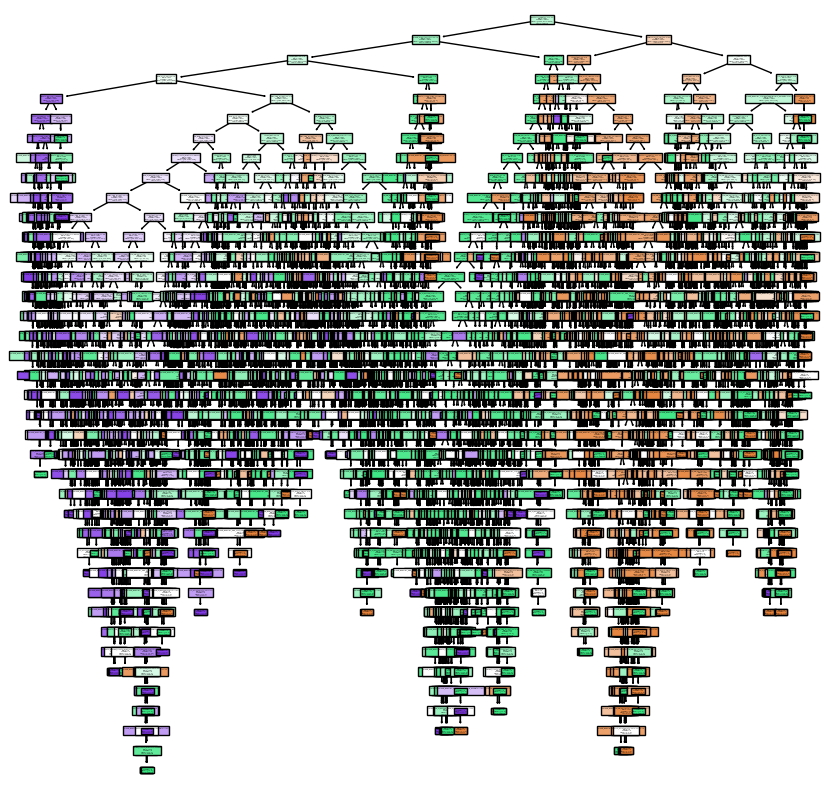

In [567]:
fig, ax = plt.subplots(1,1, figsize=(10,10))

features = df1.columns

classes = ['Poor','Standard','Good']

plot_tree(dtc, feature_names = features, class_names = classes,filled=True)
plt.savefig('Rediculous_Tree.png')
fig

In [597]:
print(f"Tree Depth: {dtc.get_depth()}")
print(f"Number of leaves : {dtc.get_n_leaves()}")
print(f"Total Number of Nodes: {dtc.tree_.node_count}")

Tree Depth: 38
Number of leaves : 7354
Total Number of Nodes: 14707


In [553]:
print(classification_report(y_test, y_prediction))

              precision    recall  f1-score   support

           0       0.74      0.64      0.69      3733
           1       0.73      0.75      0.74      6844
           2       0.54      0.62      0.57      2183

    accuracy                           0.70     12760
   macro avg       0.67      0.67      0.67     12760
weighted avg       0.70      0.70      0.70     12760



In [519]:
dtc.feature_importances_

array([0.03953545, 0.04985302, 0.02701141, 0.04148879, 0.09686143,
       0.01562419, 0.04630017, 0.0385657 , 0.06349344, 0.02787842,
       0.1752821 , 0.05253781, 0.03483085, 0.04710492, 0.05419546,
       0.05111693, 0.00318676, 0.00443473, 0.00271181, 0.00364975,
       0.00405925, 0.00437481, 0.00281906, 0.00327279, 0.0041909 ,
       0.00262538, 0.00316855, 0.00403523, 0.00415679, 0.00408952,
       0.00290576, 0.00416282, 0.00292494, 0.00174861, 0.0432321 ,
       0.00479382, 0.00273789, 0.00604249, 0.00462836, 0.00424116,
       0.00463729, 0.00548935])

In [521]:
X.columns

Index(['Age', 'Monthly_Inhand_Salary', 'Num_Bank_Accounts', 'Num_Credit_Card',
       'Interest_Rate', 'Num_of_Loan', 'Delay_from_due_date',
       'Num_of_Delayed_Payment', 'Changed_Credit_Limit',
       'Num_Credit_Inquiries', 'Outstanding_Debt', 'Credit_Utilization_Ratio',
       'Credit_History_Age', 'Total_EMI_per_month', 'Amount_invested_monthly',
       'Monthly_Balance', 'Occupation_Accountant', 'Occupation_Architect',
       'Occupation_Developer', 'Occupation_Doctor', 'Occupation_Engineer',
       'Occupation_Entrepreneur', 'Occupation_Journalist', 'Occupation_Lawyer',
       'Occupation_Manager', 'Occupation_Mechanic', 'Occupation_Media_Manager',
       'Occupation_Musician', 'Occupation_Scientist', 'Occupation_Teacher',
       'Occupation_Writer', 'Occupation________', 'Payment_of_Min_Amount_NM',
       'Payment_of_Min_Amount_No', 'Payment_of_Min_Amount_Yes',
       'Payment_Behaviour_!@9#%8',
       'Payment_Behaviour_High_spent_Large_value_payments',
       'Payment_Behav

In [523]:
feature_importance = pd.DataFrame(dtc.feature_importances_, index=X.columns)

In [525]:
feature_importance

,0
Age,0.039535
Monthly_Inhand_Salary,0.049853
Num_Bank_Accounts,0.027011
Num_Credit_Card,0.041489
Interest_Rate,0.096861
Num_of_Loan,0.015624
Delay_from_due_date,0.046300
Num_of_Delayed_Payment,0.038566
Changed_Credit_Limit,0.063493
Num_Credit_Inquiries,0.027878


In [527]:
dtc.get_params()

{'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': None,
 'max_features': None,
 'max_leaf_nodes': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'random_state': 0,
 'splitter': 'best'}

In [529]:
len(final_features)

11

Now I will try adjusting the hyperparamters of the decision tree algorthim. I will try different values of alpha to penalise tree complexity and overfitting and encourage pruning. I will not change the class_weight. I will use the gini criterion for deciding optimal notes as it is simpler and taugth. I will change the max depth. I will set max_feature to 42 which are the number of features of the data set because this means it considers all the data to determine the best split//I will then remove less important features in a final model. I will leave max_leaf_nodes unlimited. min_impurity_decrease I will change but keep it small. I will change min_sample_leaf, min_sample_split. Leave min_weight_fraction_leaf as defult 0. Monotonic_cst, and random state as default. Splitter will be set to best.

In [388]:
param_grid = {
    "ccp_alpha": [0.0001, 0.001],
    "class_weight": [None],
    "criterion": ['gini'],
    "max_depth": [5,10,15,20],
    "max_features": [10,20,42],
    "max_leaf_nodes": [15,20],
    "min_impurity_decrease": [0,0.0001,0.001],
    "min_samples_leaf": [1,5,10],
    "min_samples_split": [10,20,30],
    "min_weight_fraction_leaf": [0],
    "monotonic_cst": [None],
    "random_state": [None],
    "splitter": ['best']
    
}

grid_search = GridSearchCV(dtc, param_grid, cv=2)
grid_search.fit(x_train,y_train)

print("Best parameters:", grid_search.best_params_)
print('Best Model Accuracy:', grid_search.best_score_)

Best parameters: {'ccp_alpha': 0.0001, 'class_weight': None, 'criterion': 'gini', 'max_depth': 5, 'max_features': 10, 'max_leaf_nodes': 15, 'min_impurity_decrease': 0, 'min_samples_leaf': 1, 'min_samples_split': 10, 'min_weight_fraction_leaf': 0, 'monotonic_cst': None, 'random_state': None, 'splitter': 'best'}
Best Model Accuracy: 1.0


In [389]:
print('Best Model Accuracy:', grid_search.best_score_)

Best Model Accuracy: 1.0


In [531]:
dtc = DecisionTreeClassifier(ccp_alpha=0.0001, class_weight=None, criterion='gini', max_depth=10, max_features=15, 
                             max_leaf_nodes=20, min_impurity_decrease= 0, min_samples_leaf=10, min_samples_split= 10,
                             min_weight_fraction_leaf= 0, monotonic_cst=None, random_state= None, splitter= 'best')

dtc.fit(x_train,y_train)

y_train_pred = dtc.predict(x_train)

y_prediction = dtc.predict(x_test)

In [533]:
print(classes)
print(features)

['Poor', 'Standard', 'Good']
Index(['Age', 'Monthly_Inhand_Salary', 'Num_Bank_Accounts', 'Num_Credit_Card',
       'Interest_Rate', 'Num_of_Loan', 'Delay_from_due_date',
       'Num_of_Delayed_Payment', 'Changed_Credit_Limit',
       'Num_Credit_Inquiries', 'Outstanding_Debt', 'Credit_Utilization_Ratio',
       'Credit_History_Age', 'Total_EMI_per_month', 'Amount_invested_monthly',
       'Monthly_Balance', 'Credit_Score', 'Occupation_Accountant',
       'Occupation_Architect', 'Occupation_Developer', 'Occupation_Doctor',
       'Occupation_Engineer', 'Occupation_Entrepreneur',
       'Occupation_Journalist', 'Occupation_Lawyer', 'Occupation_Manager',
       'Occupation_Mechanic', 'Occupation_Media_Manager',
       'Occupation_Musician', 'Occupation_Scientist', 'Occupation_Teacher',
       'Occupation_Writer', 'Occupation________', 'Payment_of_Min_Amount_NM',
       'Payment_of_Min_Amount_No', 'Payment_of_Min_Amount_Yes',
       'Payment_Behaviour_!@9#%8',
       'Payment_Behaviour_Hig

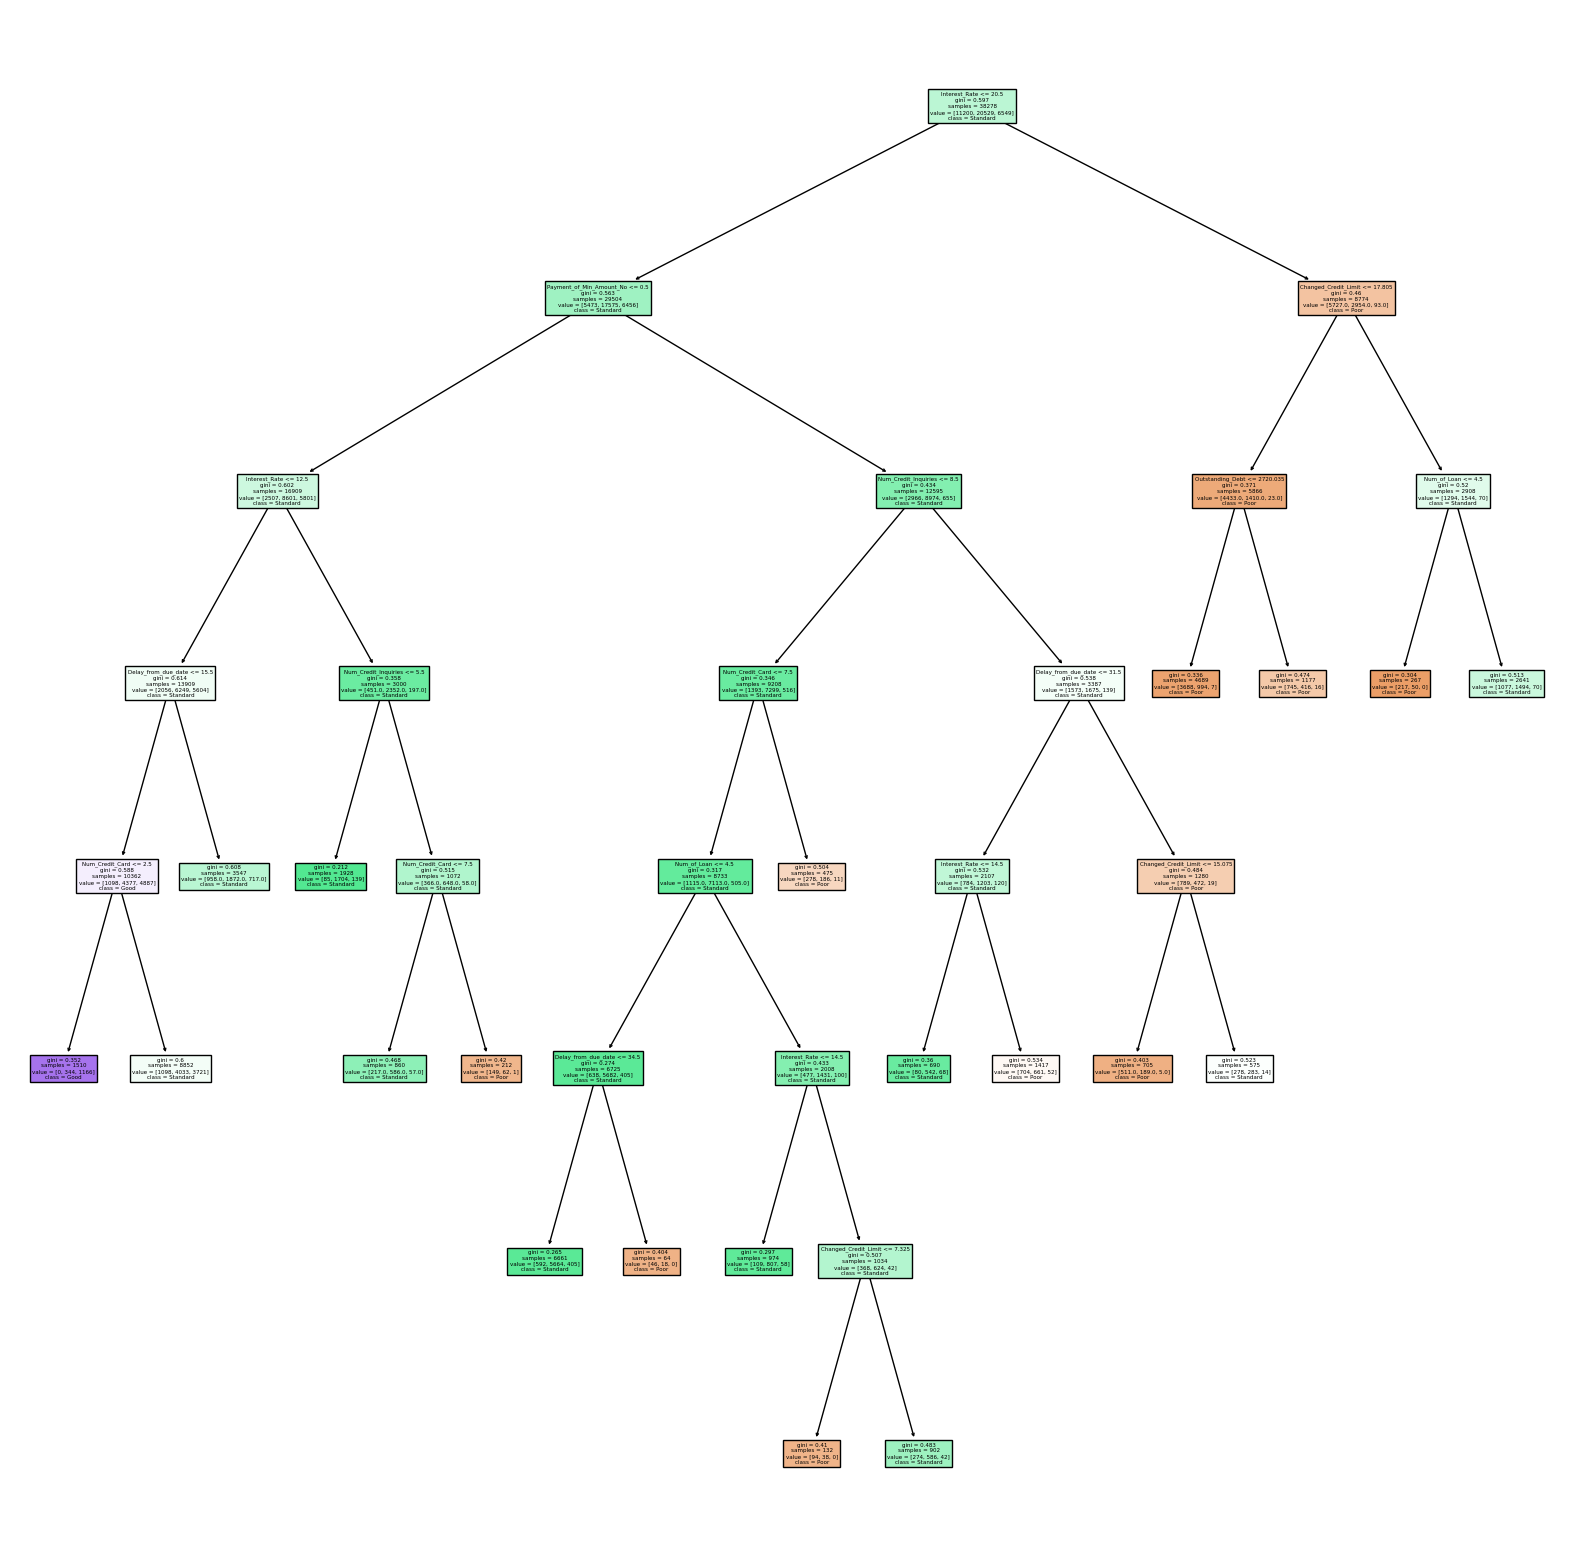

In [535]:
fig, ax = plt.subplots(1,1, figsize=(20,20))

plot_tree(dtc, feature_names = features, class_names = classes,filled=True)

fig

In [537]:
print(classification_report(y_test, y_prediction))

              precision    recall  f1-score   support

           0       0.70      0.59      0.64      3733
           1       0.64      0.85      0.73      6844
           2       0.77      0.17      0.28      2183

    accuracy                           0.66     12760
   macro avg       0.70      0.54      0.55     12760
weighted avg       0.68      0.66      0.63     12760



In [539]:
feature_importance_dic = {'Importance':dtc.feature_importances_}

feature_importance2 = pd.DataFrame(feature_importance_dic, index=X.columns)

feature_importance2.sort_values(by='Importance', ascending=False)

,Importance
Interest_Rate,0.492380
Payment_of_Min_Amount_Yes,0.161182
Num_Credit_Inquiries,0.096464
Num_Credit_Card,0.080524
Changed_Credit_Limit,0.070325
Delay_from_due_date,0.070022
Num_of_Loan,0.022242
Outstanding_Debt,0.006863
Age,0.000000
Payment_of_Min_Amount_No,0.000000


In [605]:
final_features = ['Outstanding_Debt','Payment_of_Min_Amount_Yes','Interest_Rate',
                  'Delay_from_due_date', 'Num_Credit_Card', 'Changed_Credit_Limit',
                  'Num_Bank_Accounts','Num_of_Delayed_Payment','Payment_of_Min_Amount_NM',
                  'Num_Credit_Inquiries','Total_EMI_per_month']

In [607]:
X = df1[final_features]
y = df1['Credit_Score']

x_train, x_test, y_train, y_test = train_test_split(X,y, stratify=y)

In [609]:
param_grid = {
    "ccp_alpha": [0.0001, 0.001],
    "class_weight": [None],
    "criterion": ['gini'],
    "max_depth": [5,10,15],
    "max_features": [5,11,15],
    "max_leaf_nodes": [10,15,20],
    "min_impurity_decrease": [0,0.0001,0.001],
    "min_samples_leaf": [1,5,10],
    "min_samples_split": [10,20,30],
    "min_weight_fraction_leaf": [0],
    "monotonic_cst": [None],
    "random_state": [None],
    "splitter": ['best']
    
}

grid_search = GridSearchCV(dtc, param_grid, cv=2)
grid_search.fit(x_train,y_train)

print("Best parameters:", grid_search.best_params_)
print('Best Model Accuracy:', grid_search.best_score_)

Best parameters: {'ccp_alpha': 0.0001, 'class_weight': None, 'criterion': 'gini', 'max_depth': 10, 'max_features': 11, 'max_leaf_nodes': 20, 'min_impurity_decrease': 0, 'min_samples_leaf': 1, 'min_samples_split': 10, 'min_weight_fraction_leaf': 0, 'monotonic_cst': None, 'random_state': None, 'splitter': 'best'}
Best Model Accuracy: 0.6895083337687444


* max depth = the number of layers of the decision tree
* max features = the number of variables to decide the optimal split
* max leaf nodes = the max numbe of final nodes
* 

In [575]:
dtc = DecisionTreeClassifier(ccp_alpha=0.0001, class_weight=None, criterion='gini', max_depth=10, max_features=11, 
                             max_leaf_nodes=20, min_impurity_decrease= 0, min_samples_leaf=10, min_samples_split= 10,
                             min_weight_fraction_leaf= 0, monotonic_cst=None, random_state=1, splitter= 'best')

dtc.fit(x_train,y_train)

y_train_pred = dtc.predict(x_train)

y_prediction = dtc.predict(x_test)

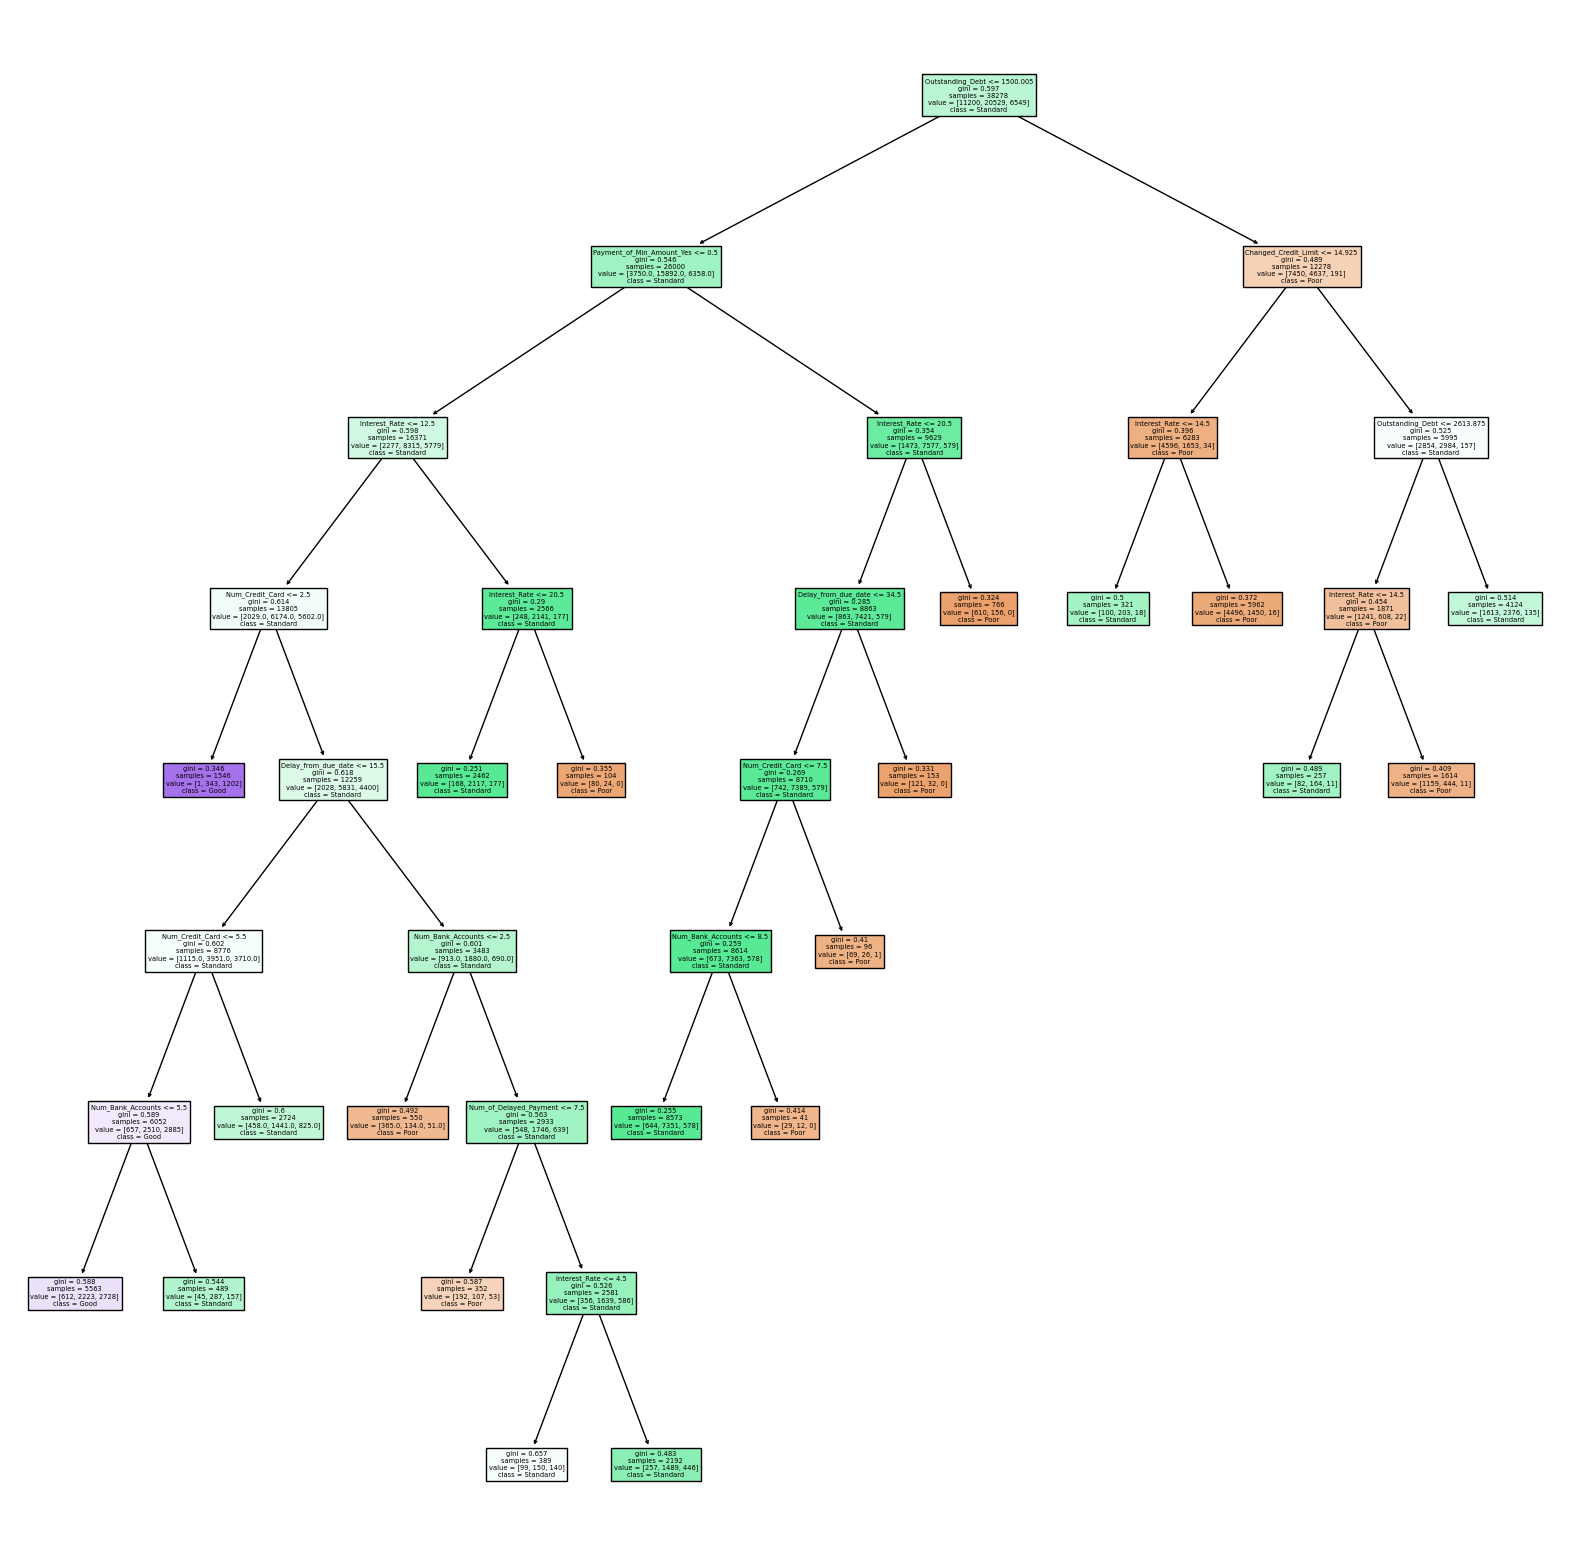

In [577]:
fig, ax = plt.subplots(1,1, figsize=(20,20))

features = final_features

plot_tree(dtc, feature_names = features, class_names = classes,filled=True)
plt.savefig('Final_Tree.png')
fig

In [579]:
print(f"Tree Depth: {dtc.get_depth()}")
print(f"Number of leaves : {dtc.get_n_leaves()}")
print(f"Total Number of Nodes: {dtc.tree_.node_count}")

Tree Depth: 8
Number of leaves : 20
Total Number of Nodes: 39


In [617]:
dtc.feature_importances_

array([0.        , 0.00346336, 0.00359134, 0.12323243, 0.06235084,
       0.        , 0.04529405, 0.0075925 , 0.        , 0.03784975,
       0.5371523 , 0.        , 0.        , 0.00555197, 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.03971008, 0.13421139, 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        ])

In [581]:
print(classification_report(y_test, y_prediction))

              precision    recall  f1-score   support

           0       0.74      0.64      0.69      3733
           1       0.72      0.75      0.73      6844
           2       0.54      0.59      0.57      2183

    accuracy                           0.69     12760
   macro avg       0.67      0.66      0.66     12760
weighted avg       0.69      0.69      0.69     12760



## Prediction

In [583]:
my_details2 = {'Outstanding_Debt':48189.49,'Payment_of_Min_Amount_Yes':0,'Interest_Rate':5,
                  'Delay_from_due_date':0, 'Num_Credit_Card':0, 'Changed_Credit_Limit':0,
                  'Num_Bank_Accounts':4,'Num_of_Delayed_Payment':0,'Payment_of_Min_Amount_NM':1,
                  'Num_Credit_Inquiries':0,'Total_EMI_per_month':0}
input_data2 = pd.DataFrame([my_details2])

In [585]:
prediction = dtc.predict(input_data2)
prediction_probability = dtc.predict_proba(input_data2)

print(f"Prediction credit score class: {prediction[0]}")
print(f"Prediction credit score class probability: {prediction_probability[0].round(2)}")

Prediction credit score class: 1
Prediction credit score class probability: [0.31 0.63 0.06]
